# 05. Benchmark exploratoire de cinq prévisions de `RV5`

> **English Overview (Step 5 — Five-Model Forecast Benchmark):** Evaluates five forecasting specifications (`Constante`, `HV20`, calibrated `EWMA`, linear `Ridge` on `HV5, HV20, HV60`, and shallow `Gradient Boosting`, plus 56 hyperparameter configurations across the three tunable families) on 2016–2019. Shows that model ranking depends on the evaluation criterion (`EWMA` lowest global MAE 4.295; `Ridge` lowest global RMSE 6.089; `HV20` lowest `Q5` MAE 9.243) and that >=4 of 5 models fail simultaneously on 44 dates across 13 contiguous episodes.

**Question :** à partir de la même série de rendements connue à la date $t$, l'EWMA, la Ridge ou le Gradient Boosting améliorent-ils seulement la précision moyenne, ou également la fiabilité conditionnelle par rapport à la constante et à la volatilité historique 20 séances ?

L'évaluation 2016–2019 est **exploratoire** : cette période a déjà été examinée. Les cinq approches partagent la source, la cible et les dates d'évaluation, mais pas une transformation strictement identique de l'information. Ridge et Gradient Boosting utilisent uniquement `HV5`, `HV20` et `HV60`; l'EWMA applique sa propre pondération exponentielle aux rendements passés.

## 1. Protocole fixé avant l'évaluation

- estimation : 1990–2009, cibles entièrement terminées en 2009;
- validation : 2010–2015, cibles entièrement terminées en 2015;
- réestimation finale : 1990–2015;
- évaluation exploratoire : 2016–2019, exactement 1 001 dates;
- sélection des paramètres : RMSE de validation uniquement;
- aucune optimisation et aucun réentraînement sur 2016–2019;
- prévisions ML négatives ramenées à zéro, avec comptage des corrections.

Le seuil absolu commun de grande erreur est le **90e centile de l'erreur absolue de la constante sur 2010–2015**. Il est ancré sur la référence la plus simple, fixé avant 2016 et identique pour tous les modèles. Contrairement aux déciles propres à chaque modèle, il n'impose pas mécaniquement la même fréquence d'échec.

In [1]:
from datetime import datetime, timezone
from hashlib import sha256
from io import BytesIO, StringIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SOURCE_URL = (
    'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/'
    'F-F_Research_Data_Factors_daily_CSV.zip'
)
EXPECTED_SHA256 = '2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db'
SNAPSHOT_FILENAME = (
    'F-F_Research_Data_Factors_daily_202608_'
    f'sha256-{EXPECTED_SHA256}.zip'
)
HORIZON = 5
ANNUALIZATION_DAYS = 252
FEATURES = ['hv_5', 'hv_20', 'hv_60']
EWMA_LAMBDAS = [0.90, 0.94, 0.97, 0.99]
RIDGE_ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0]
GB_CONFIGS = [
    {'max_depth': depth, 'min_samples_leaf': leaf}
    for depth in [1, 2] for leaf in [10, 30]
]
MODEL_NAMES = ['Constante', 'HV20', 'EWMA', 'Ridge', 'Gradient Boosting']
RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid')
print(f'pandas={pd.__version__}; numpy={np.__version__}; scikit-learn={sklearn.__version__}')

pandas=2.2.3; numpy=2.2.1; scikit-learn=1.6.1


## 2. Données, cible et variables connues à `t`

In [2]:
loaded_at_utc = datetime.now(timezone.utc).isoformat()
snapshot_candidates = [
    Path('data/raw/fama_french') / SNAPSHOT_FILENAME,
    Path('../data/raw/fama_french') / SNAPSHOT_FILENAME,
]
local_snapshot = next((path for path in snapshot_candidates if path.is_file()), None)
if local_snapshot is not None:
    archive_bytes = local_snapshot.read_bytes()
    data_origin = f'copie locale immuable : {local_snapshot.as_posix()}'
else:
    with urlopen(SOURCE_URL, timeout=60) as response:
        archive_bytes = response.read()
    data_origin = 'téléchargement en mémoire depuis la source officielle'

archive_sha256 = sha256(archive_bytes).hexdigest()
assert archive_sha256 == EXPECTED_SHA256
with ZipFile(BytesIO(archive_bytes)) as archive:
    members = archive.namelist()
    assert len(members) == 1
    text = archive.read(members[0]).decode('utf-8-sig')

lines = text.splitlines()
header_index = next(i for i, line in enumerate(lines) if line.strip().startswith(',Mkt-RF'))
data_lines = [lines[header_index]]
for line in lines[header_index + 1:]:
    first_field = line.split(',', 1)[0].strip()
    if len(first_field) == 8 and first_field.isdigit():
        data_lines.append(line)
    else:
        break

factors = pd.read_csv(StringIO('\n'.join(data_lines)))
factors = factors.rename(columns={factors.columns[0]: 'date'})
factors['date'] = pd.to_datetime(factors['date'].astype(str), format='%Y%m%d', errors='raise')
factors = factors.set_index('date')
assert factors.index.is_monotonic_increasing and not factors.index.has_duplicates
assert factors[['Mkt-RF', 'RF']].notna().all().all()
market_return = (factors['Mkt-RF'] + factors['RF']) / 100.0

print(f'Millésime : {lines[0]}')
print(f'Origine : {data_origin}')
print(f'Chargé à : {loaded_at_utc}')
print(f'SHA-256 : {archive_sha256}')
print(f'Observations : {len(factors):,}')

Millésime : This file was created by using the 202608 CRSP database.
Origine : copie locale immuable : data/raw/fama_french/F-F_Research_Data_Factors_daily_202608_sha256-2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db.zip
Chargé à : 2026-10-18T02:00:59.853895+00:00
SHA-256 : 2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db
Observations : 26,317


In [3]:
future_returns = pd.concat(
    {f'r_t_plus_{k}': market_return.shift(-k) for k in range(1, HORIZON + 1)},
    axis=1,
)
rv_5 = np.sqrt(
    (ANNUALIZATION_DAYS / HORIZON)
    * future_returns.pow(2).sum(axis=1, min_count=HORIZON)
)

data = pd.DataFrame(index=factors.index)
data['market_return'] = market_return
for window in [5, 20, 60]:
    data[f'hv_{window}'] = np.sqrt(
        (ANNUALIZATION_DAYS / window)
        * market_return.pow(2).rolling(window, min_periods=window).sum()
    )
dates = factors.index.to_series(index=factors.index)
data['rv_5'] = rv_5
data['target_start'] = dates.shift(-1)
data['target_end'] = dates.shift(-HORIZON)

assert (data.loc[data.rv_5.notna(), 'target_start'] > data.index[data.rv_5.notna()]).all()
for window in [5, 20, 60]:
    first_valid = data[f'hv_{window}'].first_valid_index()
    position = factors.index.get_loc(first_valid)
    expected = np.sqrt(
        (ANNUALIZATION_DAYS / window)
        * np.square(market_return.iloc[position-window+1:position+1]).sum()
    )
    assert np.isclose(data.loc[first_valid, f'hv_{window}'], expected)

print('HV5/HV20/HV60 : rendements jusqu’à t inclus.')
print('RV5 : cinq séances strictement futures, t+1 à t+5.')

HV5/HV20/HV60 : rendements jusqu’à t inclus.
RV5 : cinq séances strictement futures, t+1 à t+5.


## 3. Séparation chronologique et purge

Une origine n'entre dans une période que si sa cinquième séance future se termine avant la frontière correspondante. Les rendements antérieurs à 1990 servent uniquement à construire les historiques disponibles au début de l'estimation.

In [4]:
required = FEATURES + ['rv_5', 'target_start', 'target_end']
estimation = data.loc[
    (data.index >= '1990-01-01') & (data.target_end <= '2009-12-31'), required
].dropna().copy()
validation = data.loc[
    (data.index >= '2010-01-01') & (data.target_end <= '2015-12-31'), required
].dropna().copy()
development = data.loc[
    (data.index >= '1990-01-01') & (data.target_end <= '2015-12-31'), required
].dropna().copy()
evaluation = data.loc[
    (data.index >= '2016-01-01') & (data.target_end <= '2019-12-31'), required
].dropna().copy()

assert estimation.target_end.max() <= pd.Timestamp('2009-12-31')
assert validation.index.min() >= pd.Timestamp('2010-01-01')
assert validation.target_end.max() <= pd.Timestamp('2015-12-31')
assert development.target_end.max() <= pd.Timestamp('2015-12-31')
assert evaluation.index.min() >= pd.Timestamp('2016-01-01')
assert evaluation.target_end.max() <= pd.Timestamp('2019-12-31')
assert len(development) == 6548
assert len(evaluation) == 1001

periods = pd.DataFrame({
    'origine_min': [x.index.min() for x in [estimation, validation, development, evaluation]],
    'origine_max': [x.index.max() for x in [estimation, validation, development, evaluation]],
    'fin_cible_max': [x.target_end.max() for x in [estimation, validation, development, evaluation]],
    'n': [len(x) for x in [estimation, validation, development, evaluation]],
}, index=['estimation', 'validation', 'réestimation', 'évaluation'])
print(periods.to_string())

             origine_min origine_max fin_cible_max     n
estimation    1990-01-02  2009-12-23    2009-12-31  5038
validation    2010-01-04  2015-12-23    2015-12-31  1505
réestimation  1990-01-02  2015-12-23    2015-12-31  6548
évaluation    2016-01-04  2019-12-23    2019-12-31  1001


## 4. Ajustement restreint sur 1990–2015

Pour chaque modèle ajusté, le paramètre minimise exclusivement la RMSE de validation. Les prévisions négatives de Ridge ou du Boosting sont ramenées à zéro avant le calcul de cette RMSE, selon la règle fixée avant l'évaluation.

In [5]:
def rmse(observed, forecast):
    return float(np.sqrt(np.mean(np.square(np.asarray(forecast) - np.asarray(observed)))))

def positive_scale_least_squares(base_forecast, observed):
    base = np.asarray(base_forecast, dtype=float)
    target = np.asarray(observed, dtype=float)
    denominator = float(base @ base)
    assert denominator > 0
    return max(float(base @ target / denominator), np.finfo(float).eps)

def ewma_path(returns, lam, first_origin, initial_window=60):
    first_position = returns.index.get_loc(first_origin)
    history = returns.iloc[first_position-initial_window:first_position]
    assert len(history) == initial_window and history.index.max() < first_origin
    variance_previous = float(np.square(history).mean())
    output = pd.Series(index=returns.index, dtype=float)
    for date, value in returns.iloc[first_position:].items():
        variance_previous = lam * variance_previous + (1 - lam) * value ** 2
        output.loc[date] = np.sqrt(ANNUALIZATION_DAYS * variance_previous)
    return output, float(np.square(history).mean())

def clipped_prediction(model, frame):
    raw = model.predict(frame[FEATURES])
    return raw, np.maximum(raw, 0.0)

### 4.1. EWMA

Pour chaque $\lambda$, la variance précédant la première origine de 1990 est initialisée par la moyenne des rendements au carré des 60 séances immédiatement antérieures. La récursion commence ensuite avec le rendement de chaque date $t$.

Le facteur positif $c$ minimise la somme des erreurs quadratiques sur l'estimation :

$$c=\max\left(arepsilon,rac{\sum_t b_tRV5_t}{\sum_t b_t^2}ight),$$

où $b_t$ est l'EWMA annualisée brute. Cette solution fermée évite toute optimisation supplémentaire. Chaque $c$ est estimé sur 1990–2009; $\lambda$ est choisi par RMSE sur 2010–2015.

In [6]:
ewma_paths = {}
ewma_rows = []
for lam in EWMA_LAMBDAS:
    path, initial_variance = ewma_path(market_return, lam, estimation.index.min())
    ewma_paths[lam] = path
    c_estimation = positive_scale_least_squares(path.loc[estimation.index], estimation.rv_5)
    validation_forecast = c_estimation * path.loc[validation.index]
    ewma_rows.append({
        'lambda': lam,
        'variance_initiale': initial_variance,
        'volatilité_initiale_annualisée_pct': 100 * np.sqrt(ANNUALIZATION_DAYS * initial_variance),
        'c_estimation': c_estimation,
        'RMSE_validation_pct': 100 * rmse(validation.rv_5, validation_forecast),
    })
ewma_selection = pd.DataFrame(ewma_rows).sort_values(['RMSE_validation_pct', 'lambda'])
selected_lambda = float(ewma_selection.iloc[0]['lambda'])
print(ewma_selection.round(5).to_string(index=False))
print(f'Lambda retenu : {selected_lambda:.2f}')

 lambda  variance_initiale  volatilité_initiale_annualisée_pct  c_estimation  RMSE_validation_pct
   0.90            0.00009                            15.24819       0.92733              6.81452
   0.94            0.00009                            15.24819       0.92530              6.89644
   0.97            0.00009                            15.24819       0.91794              7.17030
   0.99            0.00009                            15.24819       0.90632              7.82851
Lambda retenu : 0.90


### 4.2. Ridge

In [7]:
ridge_rows = []
for alpha in RIDGE_ALPHAS:
    model = Pipeline([
        ('standardisation', StandardScaler()),
        ('ridge', Ridge(alpha=alpha)),
    ])
    model.fit(estimation[FEATURES], estimation.rv_5)
    raw, forecast = clipped_prediction(model, validation)
    ridge_rows.append({
        'alpha': alpha,
        'RMSE_validation_pct': 100 * rmse(validation.rv_5, forecast),
        'prévisions_négatives_validation': int((raw < 0).sum()),
    })
ridge_selection = pd.DataFrame(ridge_rows).sort_values(['RMSE_validation_pct', 'alpha'])
selected_alpha = float(ridge_selection.iloc[0]['alpha'])
print(ridge_selection.round(5).to_string(index=False))
print(f'Alpha retenu : {selected_alpha:g}')

 alpha  RMSE_validation_pct  prévisions_négatives_validation
100.00              6.71424                                0
 10.00              6.71994                                0
  1.00              6.72063                                0
  0.10              6.72070                                0
  0.01              6.72071                                0
Alpha retenu : 100


### 4.3. Gradient Boosting

In [8]:
gb_rows = []
for config in GB_CONFIGS:
    model = GradientBoostingRegressor(
        loss='squared_error', learning_rate=0.05, n_estimators=100,
        random_state=RANDOM_STATE, **config,
    )
    model.fit(estimation[FEATURES], estimation.rv_5)
    raw, forecast = clipped_prediction(model, validation)
    gb_rows.append({
        **config,
        'RMSE_validation_pct': 100 * rmse(validation.rv_5, forecast),
        'prévisions_négatives_validation': int((raw < 0).sum()),
    })
gb_selection = pd.DataFrame(gb_rows).sort_values(
    ['RMSE_validation_pct', 'max_depth', 'min_samples_leaf']
)
selected_gb = {
    'max_depth': int(gb_selection.iloc[0]['max_depth']),
    'min_samples_leaf': int(gb_selection.iloc[0]['min_samples_leaf']),
}
print(gb_selection.round(5).to_string(index=False))
print(f'Configuration retenue : {selected_gb}')

 max_depth  min_samples_leaf  RMSE_validation_pct  prévisions_négatives_validation
         1                10              6.72422                                0
         1                30              6.72587                                0
         2                10              6.73641                                0
         2                30              6.74345                                0
Configuration retenue : {'max_depth': 1, 'min_samples_leaf': 10}


### 4.4. Seuil absolu commun fixé sur la validation

La constante de validation est estimée uniquement sur 1990–2009. Le seuil commun est ensuite son 90e centile d'erreur absolue sur 2010–2015. Une erreur signée est définie par `prévision − RV5` : une valeur inférieure à l'opposé du seuil est une grande sous-estimation; une valeur supérieure au seuil est une grande surestimation.

In [9]:
constant_estimation = float(estimation.rv_5.mean())
validation_constant_error_pct = 100 * (constant_estimation - validation.rv_5)
COMMON_ERROR_THRESHOLD_PCT = float(validation_constant_error_pct.abs().quantile(0.90))
assert COMMON_ERROR_THRESHOLD_PCT > 0

selection_summary = pd.DataFrame({
    'élément': ['critère unique', 'lambda EWMA', 'alpha Ridge', 'profondeur Boosting',
                'feuilles min. Boosting', 'seuil absolu commun'],
    'valeur': ['RMSE validation', selected_lambda, selected_alpha,
               selected_gb['max_depth'], selected_gb['min_samples_leaf'],
               f'{COMMON_ERROR_THRESHOLD_PCT:.3f} points'],
})
print(selection_summary.to_string(index=False))

               élément          valeur
        critère unique RMSE validation
           lambda EWMA             0.9
           alpha Ridge           100.0
   profondeur Boosting               1
feuilles min. Boosting              10
   seuil absolu commun   10.931 points


## 5. Réestimation finale et concordance des références historiques

In [10]:
predictions = evaluation[['rv_5', 'target_start', 'target_end']].copy()
predictions['Constante'] = float(development.rv_5.mean())
predictions['HV20'] = evaluation.hv_20

selected_path = ewma_paths[selected_lambda]
c_final = positive_scale_least_squares(selected_path.loc[development.index], development.rv_5)
predictions['EWMA'] = c_final * selected_path.loc[evaluation.index]

ridge_final = Pipeline([
    ('standardisation', StandardScaler()),
    ('ridge', Ridge(alpha=selected_alpha)),
])
ridge_final.fit(development[FEATURES], development.rv_5)
ridge_raw, predictions['Ridge'] = clipped_prediction(ridge_final, evaluation)

gb_final = GradientBoostingRegressor(
    loss='squared_error', learning_rate=0.05, n_estimators=100,
    random_state=RANDOM_STATE, **selected_gb,
)
gb_final.fit(development[FEATURES], development.rv_5)
gb_raw, predictions['Gradient Boosting'] = clipped_prediction(gb_final, evaluation)

negative_corrections = pd.Series({
    'Ridge': int((ridge_raw < 0).sum()),
    'Gradient Boosting': int((gb_raw < 0).sum()),
}, name='prévisions_brutes_négatives_corrigées')

assert predictions[MODEL_NAMES + ['rv_5']].notna().all().all()
assert len(predictions) == 1001
assert predictions.index.equals(evaluation.index)
assert predictions.target_end.max() == pd.Timestamp('2019-12-31')

# Concordance exacte avec les notebooks 03 et 04.
assert np.isclose(100 * predictions.Constante.iloc[0], 14.775, atol=0.0005)
assert np.isclose(100 * np.mean(np.abs(predictions.Constante - predictions.rv_5)), 7.054, atol=0.0005)
assert np.isclose(100 * rmse(predictions.rv_5, predictions.Constante), 8.129, atol=0.0005)
assert np.isclose(100 * np.mean(np.abs(predictions.HV20 - predictions.rv_5)), 4.839, atol=0.0005)
assert np.isclose(100 * rmse(predictions.rv_5, predictions.HV20), 6.796, atol=0.0005)

print(f'Facteur EWMA final c (1990–2015) : {c_final:.6f}')
print(negative_corrections.to_string())
print('Concordance notebooks 03–04 : constante, HV20, 1 001 dates, MAE et RMSE vérifiées.')

Facteur EWMA final c (1990–2015) : 0.924348
Ridge                0
Gradient Boosting    0
Concordance notebooks 03–04 : constante, HV20, 1 001 dates, MAE et RMSE vérifiées.


## 6. Précision moyenne et sous-estimations

In [11]:
def model_metrics(frame, model):
    error = 100 * (frame[model] - frame.rv_5)
    shortfall = (-error).clip(lower=0)
    positive_shortfall = shortfall[shortfall > 0]
    return pd.Series({
        'n': len(frame),
        'MAE': error.abs().mean(),
        'RMSE': np.sqrt(error.pow(2).mean()),
        'biais_signé': error.mean(),
        'sous_estimation_pct': 100 * (error < 0).mean(),
        'sous_estimation_moyenne_toutes_dates': shortfall.mean(),
        'ampleur_moyenne_si_sous_estimation': positive_shortfall.mean() if len(positive_shortfall) else 0,
        'sous_estimation_maximale': shortfall.max(),
    })

global_metrics = pd.DataFrame({model: model_metrics(predictions, model) for model in MODEL_NAMES}).T
print(global_metrics.round(3).to_string())

                        n    MAE   RMSE  biais_signé  sous_estimation_pct  sous_estimation_moyenne_toutes_dates  ampleur_moyenne_si_sous_estimation  sous_estimation_maximale
Constante          1001.0  7.054  8.129        3.639               21.079                                 1.708                               8.102                    31.199
HV20               1001.0  4.839  6.796        0.873               36.663                                 1.983                               5.409                    33.904
EWMA               1001.0  4.295  6.199        0.029               40.859                                 2.133                               5.220                    34.568
Ridge              1001.0  4.368  6.089        0.750               35.365                                 1.809                               5.115                    32.885
Gradient Boosting  1001.0  4.805  6.333        1.745               26.174                                 1.530                   

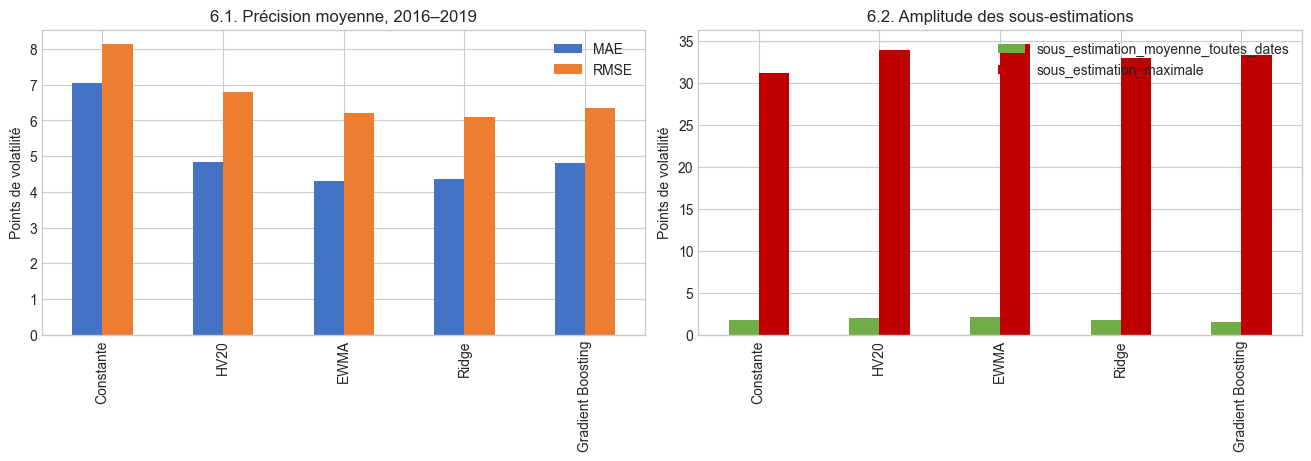

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
global_metrics[['MAE', 'RMSE']].plot.bar(ax=axes[0], color=['#4472c4', '#ed7d31'])
axes[0].set(title='6.1. Précision moyenne, 2016–2019', ylabel='Points de volatilité', xlabel='')
global_metrics[['sous_estimation_moyenne_toutes_dates', 'sous_estimation_maximale']].plot.bar(
    ax=axes[1], color=['#70ad47', '#c00000']
)
axes[1].set(title='6.2. Amplitude des sous-estimations', ylabel='Points de volatilité', xlabel='')
plt.show()

## 7. Stabilité annuelle

In [13]:
yearly_rows = []
for year, group in predictions.groupby(predictions.index.year):
    for model in MODEL_NAMES:
        values = model_metrics(group, model)
        yearly_rows.append({'année': year, 'modèle': model, **values.to_dict()})
yearly_metrics = pd.DataFrame(yearly_rows)
print(yearly_metrics[['année', 'modèle', 'n', 'MAE', 'RMSE', 'biais_signé',
                      'sous_estimation_pct', 'sous_estimation_moyenne_toutes_dates']]
      .round(3).to_string(index=False))

 année            modèle     n   MAE  RMSE  biais_signé  sous_estimation_pct  sous_estimation_moyenne_toutes_dates
  2016         Constante 252.0 6.541 7.422        3.122               23.016                                 1.710
  2016              HV20 252.0 4.681 6.811        1.257               34.524                                 1.712
  2016              EWMA 252.0 4.226 6.202        0.325               38.889                                 1.950
  2016             Ridge 252.0 4.315 6.055        0.968               34.524                                 1.674
  2016 Gradient Boosting 252.0 4.614 6.036        1.667               30.159                                 1.474
  2017         Constante 251.0 8.111 8.640        8.090                1.594                                 0.010
  2017              HV20 251.0 2.974 3.565        0.569               35.458                                 1.203
  2017              EWMA 251.0 2.838 3.496        0.011               42.231    

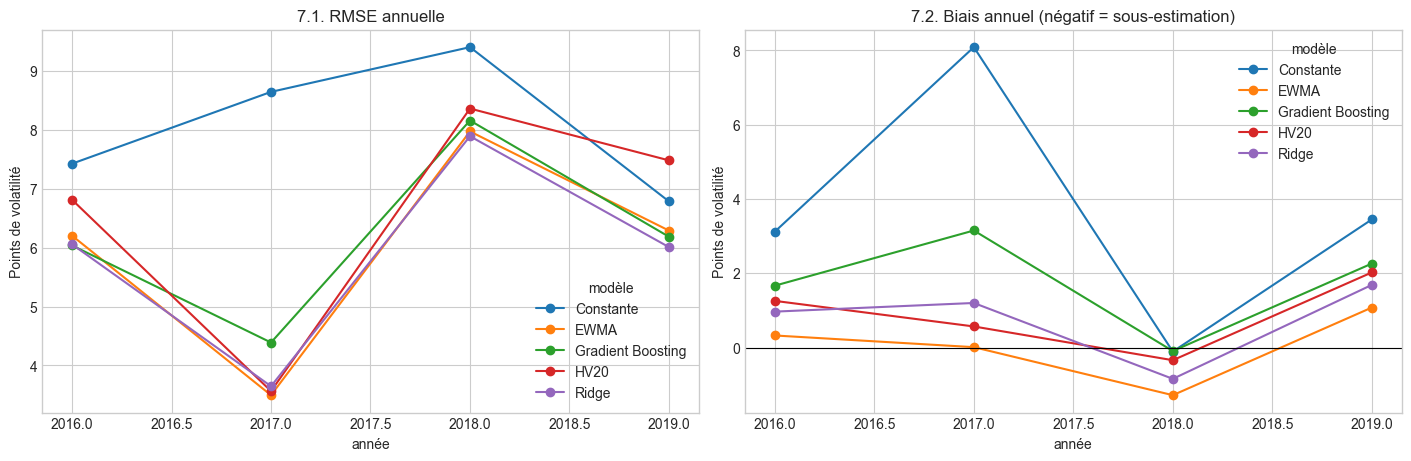

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
yearly_metrics.pivot(index='année', columns='modèle', values='RMSE').plot(ax=axes[0], marker='o')
axes[0].set(title='7.1. RMSE annuelle', ylabel='Points de volatilité')
yearly_metrics.pivot(index='année', columns='modèle', values='biais_signé').plot(ax=axes[1], marker='o')
axes[1].axhline(0, color='black', linewidth=.8)
axes[1].set(title='7.2. Biais annuel (négatif = sous-estimation)', ylabel='Points de volatilité')
plt.show()

## 8. Fiabilité conditionnelle selon les quintiles historiques de `RV5`

Les seuils sont recalculés exactement sur 1990–2015 et doivent reproduire le notebook 04. Ils décrivent après coup le niveau de la cible future; ils ne constituent pas un détecteur disponible à `t`.

In [15]:
quantile_probabilities = [.20, .40, .60, .80]
thresholds_pct = 100 * development.rv_5.quantile(quantile_probabilities)
labels = ['Q1', 'Q2', 'Q3', 'Q4', 'Q5']
predictions['niveau_rv5'] = pd.cut(
    100 * predictions.rv_5,
    bins=[-np.inf, *thresholds_pct.to_list(), np.inf],
    labels=labels, include_lowest=True,
)
assert np.allclose(thresholds_pct.to_numpy(), [7.742, 10.492, 14.126, 19.815], atol=.0005)
assert predictions.niveau_rv5.value_counts(sort=False).to_list() == [399, 206, 174, 91, 131]

def episode_count(mask):
    mask = pd.Series(mask, index=predictions.index).astype(bool)
    return int((mask & ~mask.shift(fill_value=False)).sum())

episode_table = pd.DataFrame({
    'observations': predictions.niveau_rv5.value_counts(sort=False),
    'épisodes': [episode_count(predictions.niveau_rv5.eq(level)) for level in labels],
}, index=labels)

conditional_rows = []
for level in labels:
    group = predictions.loc[predictions.niveau_rv5.eq(level)]
    for model in MODEL_NAMES:
        conditional_rows.append({'niveau': level, 'modèle': model, **model_metrics(group, model).to_dict()})
conditional_metrics = pd.DataFrame(conditional_rows)
print('Seuils (% annualisés) :', thresholds_pct.round(3).to_dict())
print('\nEffectifs et épisodes :')
print(episode_table.to_string())
print('\nMétriques conditionnelles :')
print(conditional_metrics[['niveau', 'modèle', 'n', 'MAE', 'RMSE', 'biais_signé',
                           'sous_estimation_pct', 'sous_estimation_moyenne_toutes_dates',
                           'sous_estimation_maximale']].round(3).to_string(index=False))

Seuils (% annualisés) : {0.2: 7.742, 0.4: 10.492, 0.6: 14.126, 0.8: 19.815}

Effectifs et épisodes :
    observations  épisodes
Q1           399        56
Q2           206        79
Q3           174        62
Q4            91        38
Q5           131        21

Métriques conditionnelles :
niveau            modèle     n    MAE   RMSE  biais_signé  sous_estimation_pct  sous_estimation_moyenne_toutes_dates  sous_estimation_maximale
    Q1         Constante 399.0  9.338  9.451        9.338                0.000                                 0.000                     0.000
    Q1              HV20 399.0  3.868  5.048        3.761                6.767                                 0.054                     2.266
    Q1              EWMA 399.0  3.208  4.043        3.043                9.524                                 0.083                     2.857
    Q1             Ridge 399.0  4.046  4.705        4.022                3.008                                 0.012                    

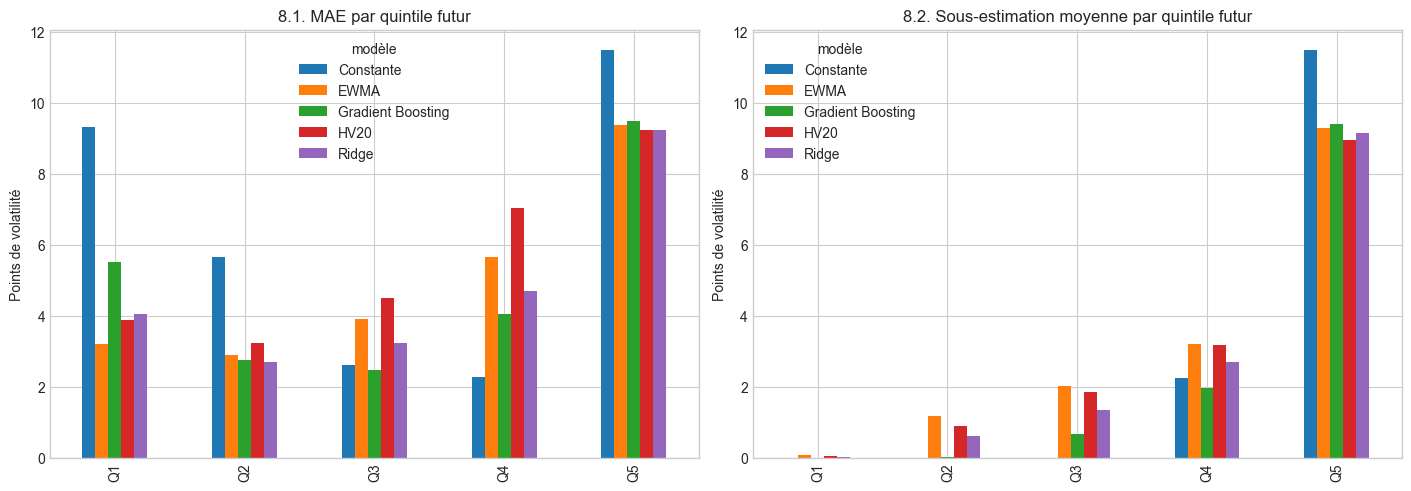

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
conditional_metrics.pivot(index='niveau', columns='modèle', values='MAE').plot.bar(ax=axes[0])
axes[0].set(title='8.1. MAE par quintile futur', ylabel='Points de volatilité', xlabel='')
conditional_metrics.pivot(index='niveau', columns='modèle', values='sous_estimation_moyenne_toutes_dates').plot.bar(ax=axes[1])
axes[1].set(title='8.2. Sous-estimation moyenne par quintile futur', ylabel='Points de volatilité', xlabel='')
plt.show()

## 9. Concentration des erreurs

In [17]:
concentration_rows = []
for model in MODEL_NAMES:
    squared_error = (100 * (predictions[model] - predictions.rv_5)).pow(2)
    total = squared_error.sum()
    ordered = squared_error.sort_values(ascending=False)
    row = {'modèle': model}
    for share in [0.01, 0.05, 0.10]:
        count = int(np.ceil(share * len(ordered)))
        row[f'part_SSE_top_{int(100*share)}pct'] = 100 * ordered.iloc[:count].sum() / total
    concentration_rows.append(row)
concentration = pd.DataFrame(concentration_rows).set_index('modèle')
print(concentration.round(2).to_string())

                   part_SSE_top_1pct  part_SSE_top_5pct  part_SSE_top_10pct
modèle                                                                     
Constante                      10.79              25.17               35.89
HV20                           16.93              45.41               62.61
EWMA                           21.02              52.08               66.34
Ridge                          20.39              49.36               62.28
Gradient Boosting              18.61              43.27               55.54


## 10. Grandes erreurs absolues et échecs communs

Le seuil absolu commun est appliqué à l'erreur signée de tous les modèles. Les sous-estimations et surestimations sont séparées. Un épisode est une suite maximale de dates d'origine consécutives dans le tableau; cela limite le double comptage descriptif sans rendre les épisodes indépendants.

In [18]:
error_pct = pd.DataFrame({
    model: 100 * (predictions[model] - predictions.rv_5) for model in MODEL_NAMES
}, index=predictions.index)
large_under = error_pct.le(-COMMON_ERROR_THRESHOLD_PCT)
large_over = error_pct.ge(COMMON_ERROR_THRESHOLD_PCT)
large_absolute = error_pct.abs().ge(COMMON_ERROR_THRESHOLD_PCT)

absolute_failure_rows = []
for model in MODEL_NAMES:
    absolute_failure_rows.append({
        'modèle': model,
        'grandes_sous_estimations': int(large_under[model].sum()),
        'épisodes_sous_estimation': episode_count(large_under[model]),
        'grandes_surestimations': int(large_over[model].sum()),
        'épisodes_surestimation': episode_count(large_over[model]),
        'grandes_erreurs_total': int(large_absolute[model].sum()),
    })
absolute_failures = pd.DataFrame(absolute_failure_rows).set_index('modèle')

common_counts = pd.DataFrame({
    'modèles_grande_sous_estimation': large_under.sum(axis=1),
    'modèles_grande_surestimation': large_over.sum(axis=1),
    'modèles_grande_erreur_absolue': large_absolute.sum(axis=1),
}, index=predictions.index)
consensus_distribution = pd.DataFrame({
    'sous_estimation': common_counts.modèles_grande_sous_estimation.value_counts().reindex(range(6), fill_value=0),
    'surestimation': common_counts.modèles_grande_surestimation.value_counts().reindex(range(6), fill_value=0),
    'erreur_absolue': common_counts.modèles_grande_erreur_absolue.value_counts().reindex(range(6), fill_value=0),
})
consensus_distribution.index.name = 'nombre_de_modèles'

common_episode_summary = pd.DataFrame({
    'observations': [
        int((common_counts.modèles_grande_sous_estimation >= 4).sum()),
        int((common_counts.modèles_grande_surestimation >= 4).sum()),
        int((common_counts.modèles_grande_erreur_absolue >= 4).sum()),
        int((common_counts.modèles_grande_sous_estimation == 5).sum()),
        int((common_counts.modèles_grande_surestimation == 5).sum()),
        int((common_counts.modèles_grande_erreur_absolue == 5).sum()),
    ],
    'épisodes': [
        episode_count(common_counts.modèles_grande_sous_estimation >= 4),
        episode_count(common_counts.modèles_grande_surestimation >= 4),
        episode_count(common_counts.modèles_grande_erreur_absolue >= 4),
        episode_count(common_counts.modèles_grande_sous_estimation == 5),
        episode_count(common_counts.modèles_grande_surestimation == 5),
        episode_count(common_counts.modèles_grande_erreur_absolue == 5),
    ],
}, index=['sous-estimation ≥4/5', 'surestimation ≥4/5', 'erreur absolue ≥4/5',
          'sous-estimation 5/5', 'surestimation 5/5', 'erreur absolue 5/5'])

print(f'Seuil absolu commun fixé sur 2010–2015 : {COMMON_ERROR_THRESHOLD_PCT:.3f} points.')
print('\nPar modèle :')
print(absolute_failures.to_string())
print('\nNombre de modèles dépassant simultanément le seuil :')
print(consensus_distribution.to_string())
print('\nÉpisodes communs :')
print(common_episode_summary.to_string())

Seuil absolu commun fixé sur 2010–2015 : 10.931 points.

Par modèle :
                   grandes_sous_estimations  épisodes_sous_estimation  grandes_surestimations  épisodes_surestimation  grandes_erreurs_total
modèle                                                                                                                                      
Constante                                57                        15                      63                      26                    120
HV20                                     53                        16                      51                       9                    104
EWMA                                     52                        16                      16                       7                     68
Ridge                                    44                        13                      12                       8                     56
Gradient Boosting                        51                        16               

In [19]:
common_dates = predictions[['target_start', 'target_end', 'rv_5']].copy()
common_dates['rv5_pct'] = 100 * common_dates.pop('rv_5')
common_dates = common_dates.join(common_counts)
common_dates = common_dates.loc[
    (common_dates.modèles_grande_sous_estimation >= 4)
    | (common_dates.modèles_grande_surestimation >= 4)
]
print(common_dates.round(3).to_string())

           target_start target_end  rv5_pct  modèles_grande_sous_estimation  modèles_grande_surestimation  modèles_grande_erreur_absolue
date                                                                                                                                    
2016-01-06   2016-01-07 2016-01-13   27.296                               4                             0                              4
2016-06-17   2016-06-20 2016-06-24   28.668                               5                             0                              5
2016-06-20   2016-06-21 2016-06-27   31.786                               5                             0                              5
2016-06-21   2016-06-22 2016-06-28   34.121                               5                             0                              5
2016-06-22   2016-06-23 2016-06-29   36.383                               5                             0                              5
2016-06-23   2016-06-24 2016-06-30   36.3

### 10.1. Diagnostic secondaire : décile propre à chaque modèle

Cette définition facilite l'étude du chevauchement des classements, mais impose environ 10 % de grandes erreurs à chaque modèle. Elle ne mesure donc pas à elle seule leur fréquence absolue d'échec.

In [20]:
relative_large = pd.DataFrame(index=predictions.index)
relative_thresholds = {}
for model in MODEL_NAMES:
    absolute_error = error_pct[model].abs()
    relative_thresholds[model] = absolute_error.quantile(.90)
    relative_large[model] = absolute_error.ge(relative_thresholds[model])
relative_overlap = relative_large.astype(int).T @ relative_large.astype(int)
print('Seuils propres (points) :')
print(pd.Series(relative_thresholds).round(3).to_string())
print('\nNombre de dates communes dans les déciles propres :')
print(relative_overlap.to_string())

Seuils propres (points) :
Constante            11.365
HV20                 11.028
EWMA                  9.133
Ridge                 8.635
Gradient Boosting     8.798

Nombre de dates communes dans les déciles propres :
                   Constante  HV20  EWMA  Ridge  Gradient Boosting
Constante                101    40    44     48                 49
HV20                      40   101    78     77                 75
EWMA                      44    78   101     86                 76
Ridge                     48    77    86    101                 79
Gradient Boosting         49    75    76     79                101


## 11. Cinq sensibilités sans chevauchement direct des cibles

In [21]:
offset_rows = []
for offset in range(HORIZON):
    spaced = predictions.iloc[offset::HORIZON].copy()
    assert (spaced.target_start.iloc[1:].to_numpy() > spaced.target_end.iloc[:-1].to_numpy()).all()
    for scope, subset in [('global', spaced), ('Q5', spaced.loc[spaced.niveau_rv5.eq('Q5')])]:
        for model in MODEL_NAMES:
            values = model_metrics(subset, model)
            offset_rows.append({
                'décalage': offset, 'périmètre': scope, 'modèle': model,
                'n': len(subset), 'MAE': values.MAE, 'RMSE': values.RMSE,
                'biais_signé': values.biais_signé,
                'sous_estimation_pct': values.sous_estimation_pct,
                'sous_estimation_moyenne': values.sous_estimation_moyenne_toutes_dates,
            })
offset_metrics = pd.DataFrame(offset_rows)
print(offset_metrics.round(3).to_string(index=False))

 décalage périmètre            modèle   n    MAE   RMSE  biais_signé  sous_estimation_pct  sous_estimation_moyenne
        0    global         Constante 201  7.026  8.159        3.645               20.896                    1.691
        0    global              HV20 201  4.988  6.777        0.886               38.806                    2.051
        0    global              EWMA 201  4.493  6.235        0.157               39.801                    2.168
        0    global             Ridge 201  4.540  6.151        0.749               35.821                    1.895
        0    global Gradient Boosting 201  4.879  6.361        1.740               26.368                    1.569
        0        Q5         Constante  25 11.605 13.106      -11.605              100.000                   11.605
        0        Q5              HV20  25  9.394 12.513       -8.960               92.000                    9.177
        0        Q5              EWMA  25  9.710 12.681       -9.587            

In [22]:
offset_ranges = offset_metrics.groupby(['périmètre', 'modèle'])[
    ['MAE', 'RMSE', 'biais_signé', 'sous_estimation_moyenne']
].agg(['min', 'max'])
print(offset_ranges.round(3).to_string())

                                MAE            RMSE         biais_signé         sous_estimation_moyenne        
                                min     max     min     max         min     max                     min     max
périmètre modèle                                                                                               
Q5        Constante          11.172  12.051  12.411  13.315     -12.051 -11.172                  11.172  12.051
          EWMA                8.445  10.075  11.401  12.982      -9.994  -8.327                   8.386  10.035
          Gradient Boosting   8.675  10.051  11.064  12.512     -10.025  -8.661                   8.668  10.025
          HV20                8.694   9.735  11.480  12.676      -9.499  -7.887                   8.290   9.617
          Ridge               8.483   9.770  11.085  12.520      -9.719  -8.400                   8.441   9.745
global    Constante           7.005   7.159   8.062   8.225       3.590   3.670                   1.691 

## 12. Lecture visuelle des prévisions

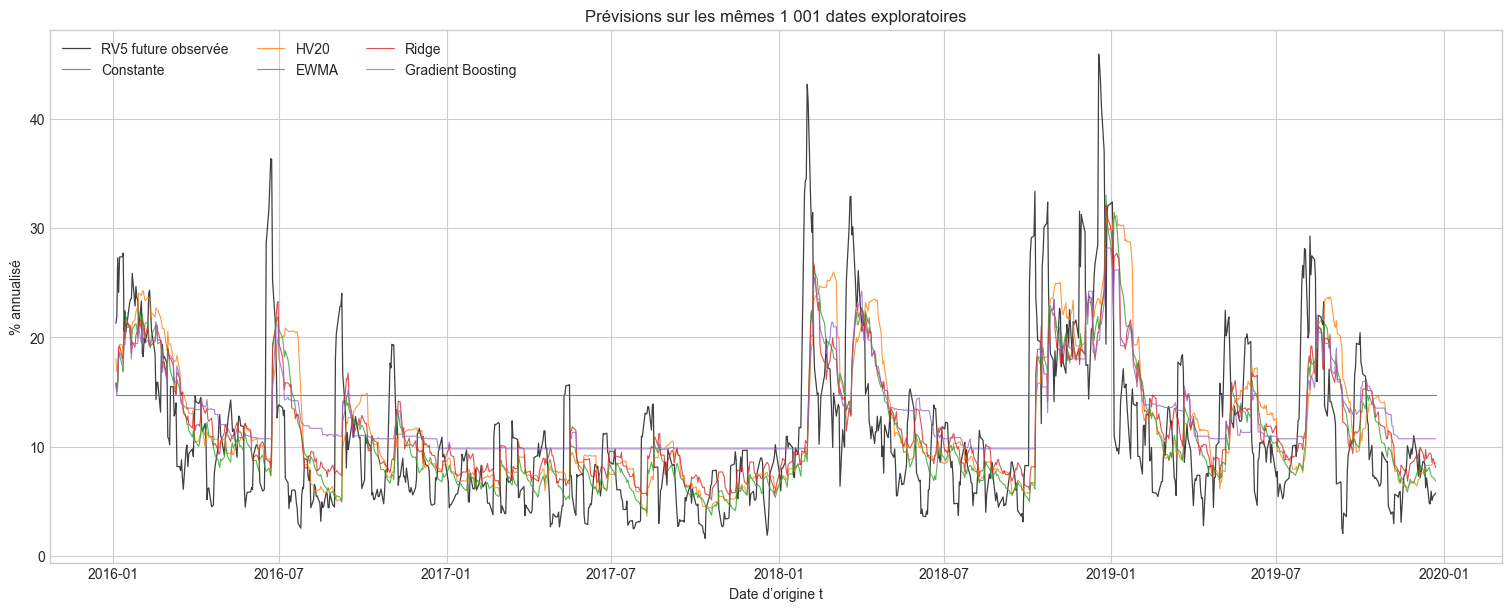

In [23]:
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
ax.plot(predictions.index, 100 * predictions.rv_5, color='black', linewidth=.9, alpha=.75, label='RV5 future observée')
for model in MODEL_NAMES:
    ax.plot(predictions.index, 100 * predictions[model], linewidth=.8, alpha=.8, label=model)
ax.set(title='Prévisions sur les mêmes 1 001 dates exploratoires', xlabel='Date d’origine t', ylabel='% annualisé')
ax.legend(ncol=3)
plt.show()

## 13. Synthèse calculée

Les lignes suivantes résument les résultats observés sans leur attribuer une valeur financière. Une forte `RV5` mesure une forte amplitude des rendements futurs, pas nécessairement une perte.

In [24]:
q5_table = conditional_metrics.loc[conditional_metrics.niveau.eq('Q5')].set_index('modèle')
best_mae = global_metrics.MAE.idxmin()
best_rmse = global_metrics.RMSE.idxmin()
lowest_shortfall = global_metrics.sous_estimation_moyenne_toutes_dates.idxmin()
most_stable_rmse = yearly_metrics.groupby('modèle').RMSE.std().idxmin()

print('RÉSULTATS EMPIRIQUES EXPLORATOIRES')
print(f'Plus faible MAE globale : {best_mae} ({global_metrics.loc[best_mae, "MAE"]:.3f}).')
print(f'Plus faible RMSE globale : {best_rmse} ({global_metrics.loc[best_rmse, "RMSE"]:.3f}).')
print(f'Plus faible sous-estimation moyenne : {lowest_shortfall} '
      f'({global_metrics.loc[lowest_shortfall, "sous_estimation_moyenne_toutes_dates"]:.3f}).')
print(f'Plus faible dispersion annuelle descriptive de RMSE : {most_stable_rmse}.')
print('\nQ5 :')
print(q5_table[['MAE', 'RMSE', 'biais_signé', 'sous_estimation_pct',
                'sous_estimation_moyenne_toutes_dates', 'sous_estimation_maximale']]
      .round(3).to_string())
print(f'\nSeuil commun : {COMMON_ERROR_THRESHOLD_PCT:.3f} points.')
print(common_episode_summary.to_string())

RÉSULTATS EMPIRIQUES EXPLORATOIRES
Plus faible MAE globale : EWMA (4.295).
Plus faible RMSE globale : Ridge (6.089).
Plus faible sous-estimation moyenne : Gradient Boosting (1.530).
Plus faible dispersion annuelle descriptive de RMSE : Constante.

Q5 :
                      MAE    RMSE  biais_signé  sous_estimation_pct  sous_estimation_moyenne_toutes_dates  sous_estimation_maximale
modèle                                                                                                                             
Constante          11.498  12.869      -11.498              100.000                                11.498                    31.199
HV20                9.243  12.335       -8.655               83.969                                 8.949                    33.904
EWMA                9.386  12.468       -9.206               91.603                                 9.296                    34.568
Ridge               9.255  12.069       -9.079               92.366                    

## 14. Interprétation critique

**Ce qui est observé.** Aucun modèle ne domine tous les critères. L'EWMA obtient la plus faible MAE globale (4,295 points), tandis que la Ridge obtient la plus faible RMSE (6,089). Le Gradient Boosting présente la sous-estimation moyenne globale la plus faible (1,530 point), mais son biais positif de 1,745 point et ses résultats conditionnels montrent que ce résultat repose aussi sur une tendance à prévoir plus haut hors de `Q5`. Aucun plancher n'a été appliqué : Ridge et Boosting n'ont produit aucune prévision négative sur l'évaluation.

**Fiabilité conditionnelle.** Dans `Q5`, les trois modèles ajoutés ne réduisent pas nettement la MAE de `HV20` (9,243) : Ridge atteint 9,255, EWMA 9,386 et Boosting 9,506. La Ridge et le Boosting abaissent légèrement la RMSE de `Q5` à 12,069 et 12,056, mais ils sous-estiment respectivement 92,4 % et 96,2 % des dates. L'amélioration moyenne apportée par la complexité ne devient donc pas une maîtrise uniforme des situations de forte volatilité future.

**Échecs communs.** Le seuil absolu fixé sur la validation vaut 10,931 points. Au moins quatre modèles connaissent une grande sous-estimation sur 44 dates regroupées en 13 épisodes; les cinq échouent ensemble sur 33 dates et 11 épisodes. Les grandes surestimations communes à au moins quatre modèles sont plus rares : 10 dates et 5 épisodes. Cette concentration est compatible avec une difficulté partagée face à certains changements rapides ou avec le bruit de `RV5`; elle ne permet pas d'identifier une cause.

**Interprétation statistique plausible.** Les résultats sont compatibles avec une utilité moyenne de plusieurs mémoires : EWMA et Ridge améliorent `HV20` globalement, et ces écarts restent visibles dans les cinq décalages non chevauchants. Le Boosting ne produit pas de gain global face aux deux approches plus simples et ne démontre donc pas ici la nécessité d'une relation non linéaire. Les erreurs carrées restent très concentrées : les 10 % les plus fortes en représentent 55,54 % à 66,34 % selon les trois nouveaux modèles.

**Implications financières seulement potentielles.** Réduire certaines sous-estimations pourrait être utile à une décision sensible au risque, mais aucune fonction de coût, stratégie, exposition ou perte financière n'est définie ici. `RV5` ignore le signe des rendements : forte volatilité et perte ne sont pas synonymes.

**Limites.** La période 2016–2019 est déjà explorée; la validation repose sur un seul bloc; `RV5` ne contient que cinq rendements et ses fenêtres se chevauchent; les quintiles et erreurs sont identifiés rétrospectivement; les cinq décalages ne sont pas cinq réplications indépendantes; la mise à jour mécanique de l'EWMA diffère de la relation Ridge/Boosting fixée après 2015. Cette expérience n'établit ni généralisation, ni détection en temps réel, ni supériorité financière, ni contribution originale.

**Question qui en découle.** Les épisodes de grande sous-estimation communs aux modèles peuvent-ils être distingués, avec l'information réellement disponible à `t`, des erreurs propres à une méthode ? Cette question est proposée mais aucune expérience supplémentaire n'est autorisée par ce notebook.

**Arrêt expérimental.** Aucune nouvelle modélisation ou extension n'est engagée après ce benchmark sans validation explicite.

## 15. Approfondissement : sensibilité et mécanismes des hyperparamètres

Cette extension **préserve le benchmark initial** et répond à une autre question : les conclusions changent-elles lorsque l'on examine la sensibilité des modèles autour et au-delà des grilles initiales ?

Toutes les nouvelles configurations sont ajustées sur 1990–2009 et comparées sur 2010–2015. Les résultats 2016–2019 ne participent jamais au choix. Comme 56 configurations sont désormais examinées sur le même bloc de validation, le minimum observé devient plus exposé au surajustement à 2010–2015. Les résultats étendus sont donc séparés du benchmark initial et restent exploratoires.

In [25]:
EWMA_EXPANDED = [0.70, 0.75, 0.80, 0.85, 0.90, 0.94, 0.97, 0.99]
RIDGE_EXPANDED = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100, 1000, 10000]
GB_LEARNING_RATES = [0.01, 0.03, 0.05, 0.10, 0.20]
GB_N_ESTIMATORS = [25, 50, 100, 200, 400]
GB_DEPTHS = [1, 2, 3]
GB_LEAVES = [5, 10, 30, 60, 120]

validation_early = validation.loc[:'2012-12-31']
validation_late = validation.loc['2013-01-01':]
high_threshold_estimation = float(estimation.rv_5.quantile(.80))
validation_high = validation.rv_5 >= high_threshold_estimation

def series_diagnostics(observed, forecast):
    error = 100 * (pd.Series(forecast, index=observed.index) - observed)
    shortfall = (-error).clip(lower=0)
    return {
        'MAE': error.abs().mean(),
        'RMSE': np.sqrt(error.pow(2).mean()),
        'biais': error.mean(),
        'sous_estimation_pct': 100 * error.lt(0).mean(),
        'sous_estimation_moyenne': shortfall.mean(),
        'sous_estimation_max': shortfall.max(),
        'variabilité_prévision': 100 * pd.Series(forecast, index=observed.index).diff().std(),
    }

def period_rmse(observed, forecast, index):
    return 100 * rmse(observed.loc[index], pd.Series(forecast, index=observed.index).loc[index])

print(f'Configurations supplémentaires examinées avant 2016 : '
      f'{len(EWMA_EXPANDED)} EWMA, {len(RIDGE_EXPANDED)} Ridge et une grille Boosting structurée.')
print(f'Seuil Q5 de diagnostic sur validation, calculé sur 1990–2009 : '
      f'{100 * high_threshold_estimation:.3f} %.')

Configurations supplémentaires examinées avant 2016 : 8 EWMA, 9 Ridge et une grille Boosting structurée.
Seuil Q5 de diagnostic sur validation, calculé sur 1990–2009 : 20.211 %.


## 16. EWMA : mémoire, réaction et compromis

Dans la variance EWMA, le poids d'un rendement au carré vieux de $k$ séances est proportionnel à $(1-\lambda)\lambda^k$. Une petite valeur de $\lambda$ réagit davantage au dernier mouvement mais oublie plus vite. Sa demi-vie théorique est $\log(0{,}5)/\log(\lambda)$ séances. Ce mécanisme est mathématique; sa performance dans nos données est une observation empirique distincte.

In [26]:
ewma_extended_paths = {}
ewma_extended_forecasts = {}
ewma_sensitivity_rows = []
for lam in EWMA_EXPANDED:
    path, initial_variance = ewma_path(market_return, lam, estimation.index.min())
    c_est = positive_scale_least_squares(path.loc[estimation.index], estimation.rv_5)
    pred_est = c_est * path.loc[estimation.index]
    pred_val = c_est * path.loc[validation.index]
    ewma_extended_paths[lam] = path
    ewma_extended_forecasts[lam] = pred_val
    diag = series_diagnostics(validation.rv_5, pred_val)
    high_diag = series_diagnostics(validation.loc[validation_high, 'rv_5'], pred_val.loc[validation_high])
    ewma_sensitivity_rows.append({
        'lambda': lam,
        'demi_vie_séances': np.log(.5) / np.log(lam),
        'c_estimation': c_est,
        'RMSE_estimation': 100 * rmse(estimation.rv_5, pred_est),
        **diag,
        'RMSE_Q5_validation': high_diag['RMSE'],
        'sous_estimation_Q5_pct': high_diag['sous_estimation_pct'],
        'RMSE_2010_2012': period_rmse(validation.rv_5, pred_val, validation_early.index),
        'RMSE_2013_2015': period_rmse(validation.rv_5, pred_val, validation_late.index),
    })
ewma_sensitivity = pd.DataFrame(ewma_sensitivity_rows).sort_values('lambda')
expanded_lambda = float(ewma_sensitivity.loc[ewma_sensitivity.RMSE.idxmin(), 'lambda'])
assert expanded_lambda in EWMA_EXPANDED
print(ewma_sensitivity.round(4).to_string(index=False))
print(f'Choix étendu par RMSE 2010–2015 uniquement : lambda={expanded_lambda:.2f}.')

 lambda  demi_vie_séances  c_estimation  RMSE_estimation    MAE   RMSE   biais  sous_estimation_pct  sous_estimation_moyenne  sous_estimation_max  variabilité_prévision  RMSE_Q5_validation  sous_estimation_Q5_pct  RMSE_2010_2012  RMSE_2013_2015
   0.70            1.9434        0.9132           7.4778 5.2161 7.1834 -1.0539              55.6146                   3.1350              56.4285                 3.1837             12.5690                 77.9528          8.1354          6.0794
   0.75            2.4094        0.9184           7.2623 5.0934 7.0368 -0.8678              54.0864                   2.9806              56.8007                 2.6853             12.3946                 77.9528          7.9491          5.9825
   0.80            3.1063        0.9227           7.0729 4.9911 6.9163 -0.6847              52.3588                   2.8379              57.3570                 2.1858             12.2767                 76.7717          7.7977          5.9002
   0.85            4

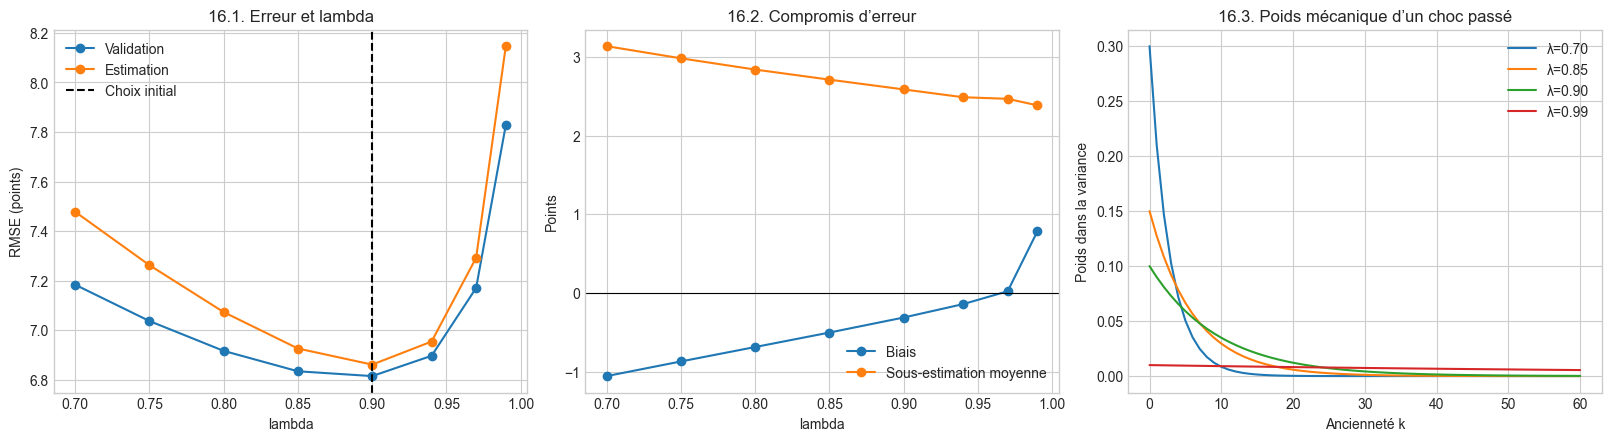

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), constrained_layout=True)
axes[0].plot(ewma_sensitivity['lambda'], ewma_sensitivity['RMSE'], marker='o', label='Validation')
axes[0].plot(ewma_sensitivity['lambda'], ewma_sensitivity['RMSE_estimation'], marker='o', label='Estimation')
axes[0].axvline(selected_lambda, color='black', linestyle='--', label='Choix initial')
axes[0].set(title='16.1. Erreur et lambda', xlabel='lambda', ylabel='RMSE (points)')
axes[0].legend()

axes[1].plot(ewma_sensitivity['lambda'], ewma_sensitivity['biais'], marker='o', label='Biais')
axes[1].plot(ewma_sensitivity['lambda'], ewma_sensitivity['sous_estimation_moyenne'], marker='o', label='Sous-estimation moyenne')
axes[1].axhline(0, color='black', linewidth=.8)
axes[1].set(title='16.2. Compromis d’erreur', xlabel='lambda', ylabel='Points')
axes[1].legend()

for lam in [0.70, 0.85, 0.90, 0.99]:
    k = np.arange(61)
    axes[2].plot(k, (1-lam) * lam**k, label=f'λ={lam:.2f}')
axes[2].set(title='16.3. Poids mécanique d’un choc passé', xlabel='Ancienneté k', ylabel='Poids dans la variance')
axes[2].legend()
plt.show()

In [28]:
ewma_subperiod_choices = pd.Series({
    '2010–2012': ewma_sensitivity.loc[ewma_sensitivity.RMSE_2010_2012.idxmin(), 'lambda'],
    '2013–2015': ewma_sensitivity.loc[ewma_sensitivity.RMSE_2013_2015.idxmin(), 'lambda'],
    '2010–2015': expanded_lambda,
}, name='lambda_min_RMSE')
print(ewma_subperiod_choices.to_string())

return_threshold = float(market_return.loc[estimation.index].abs().quantile(.99))
candidate_events = market_return.loc[validation.index].abs().sort_values(ascending=False)
event_dates = []
for date in candidate_events.index:
    position = validation.index.get_loc(date)
    if market_return.loc[date].__abs__() < return_threshold:
        break
    if all(abs(position - validation.index.get_loc(existing)) > 20 for existing in event_dates):
        event_dates.append(date)
    if len(event_dates) == 3:
        break
print(f'Seuil de forte amplitude fixé sur 1990–2009 : {100*return_threshold:.3f} %.')
print('Trois événements de validation non voisins retenus pour visualisation :')
print((100 * market_return.loc[event_dates]).round(3).to_string())

2010–2012    0.90
2013–2015    0.97
2010–2015    0.90
Seuil de forte amplitude fixé sur 1990–2009 : 4.089 %.
Trois événements de validation non voisins retenus pour visualisation :
date
2011-08-08   -6.96
2010-05-10    4.47
2011-11-30    4.44


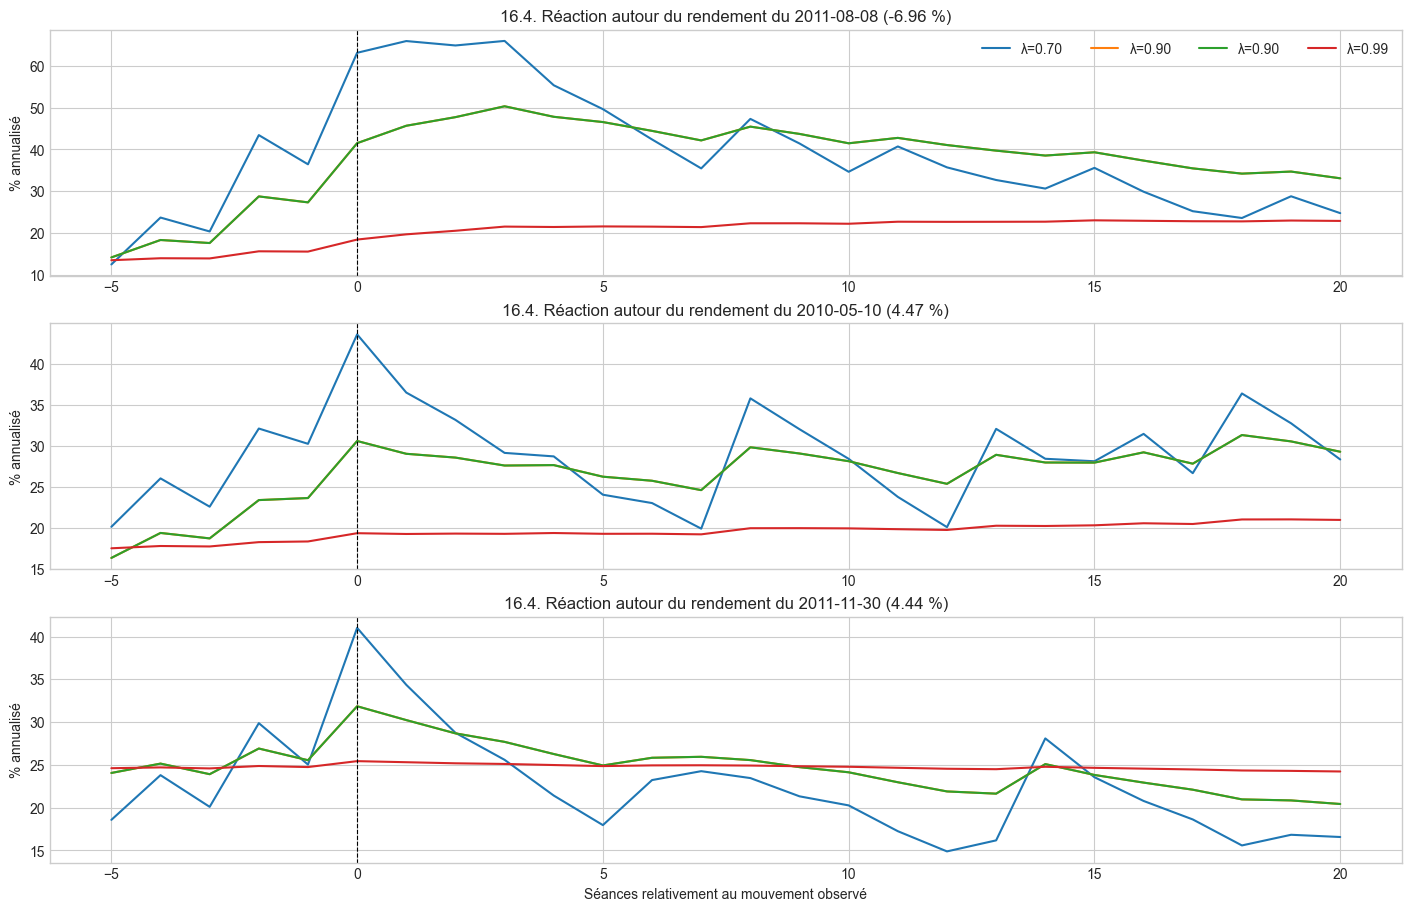

In [29]:
fig, axes = plt.subplots(len(event_dates), 1, figsize=(14, 9), constrained_layout=True)
for ax, event_date in zip(np.atleast_1d(axes), event_dates):
    center = validation.index.get_loc(event_date)
    local_index = validation.index[max(0, center-5):min(len(validation), center+21)]
    for lam in [0.70, expanded_lambda, 0.90, 0.99]:
        pred = ewma_extended_forecasts[lam]
        ax.plot(np.arange(len(local_index))-min(5, center), 100*pred.loc[local_index], label=f'λ={lam:.2f}')
    ax.axvline(0, color='black', linestyle='--', linewidth=.8)
    ax.set(title=f'16.4. Réaction autour du rendement du {event_date.date()} '
                 f'({100*market_return.loc[event_date]:.2f} %)', ylabel='% annualisé')
axes[-1].set_xlabel('Séances relativement au mouvement observé')
axes[0].legend(ncol=4)
plt.show()

## 17. Ridge : régularisation, coefficients et similitude des prévisions

Les variables sont standardisées sur l'estimation. Les coefficients deviennent donc comparables en échelle. Une hausse de `alpha` contracte les coefficients vers zéro; elle ne garantit pas une meilleure prévision. Nous comparons l'erreur d'estimation, l'erreur de validation, les coefficients et l'écart réel entre trajectoires.

In [30]:
ridge_extended_models = {}
ridge_extended_forecasts = {}
ridge_sensitivity_rows = []
ridge_coefficient_rows = []
for alpha in RIDGE_EXPANDED:
    model = Pipeline([('standardisation', StandardScaler()), ('ridge', Ridge(alpha=alpha))])
    model.fit(estimation[FEATURES], estimation.rv_5)
    raw_est, pred_est = clipped_prediction(model, estimation)
    raw_val, pred_val_array = clipped_prediction(model, validation)
    pred_val = pd.Series(pred_val_array, index=validation.index)
    ridge_extended_models[alpha] = model
    ridge_extended_forecasts[alpha] = pred_val
    diag = series_diagnostics(validation.rv_5, pred_val)
    high_diag = series_diagnostics(validation.loc[validation_high, 'rv_5'], pred_val.loc[validation_high])
    ridge_sensitivity_rows.append({
        'alpha': alpha,
        'RMSE_estimation': 100 * rmse(estimation.rv_5, pred_est),
        **diag,
        'RMSE_Q5_validation': high_diag['RMSE'],
        'sous_estimation_Q5_pct': high_diag['sous_estimation_pct'],
        'RMSE_2010_2012': period_rmse(validation.rv_5, pred_val, validation_early.index),
        'RMSE_2013_2015': period_rmse(validation.rv_5, pred_val, validation_late.index),
        'corrélation_avec_alpha100': pred_val.corr(ridge_extended_forecasts.get(100, pred_val)),
        'prévisions_négatives': int((raw_val < 0).sum()),
    })
    coefs = model.named_steps['ridge'].coef_
    ridge_coefficient_rows.append({'alpha': alpha, **dict(zip(FEATURES, coefs))})

ridge_sensitivity = pd.DataFrame(ridge_sensitivity_rows).sort_values('alpha')
ridge_coefficients = pd.DataFrame(ridge_coefficient_rows).set_index('alpha')
reference_ridge_forecast = ridge_extended_forecasts[100]
ridge_sensitivity['corrélation_avec_alpha100'] = [
    ridge_extended_forecasts[a].corr(reference_ridge_forecast) for a in ridge_sensitivity.alpha
]
ridge_sensitivity['écart_moyen_abs_avec_alpha100'] = [
    100 * (ridge_extended_forecasts[a] - reference_ridge_forecast).abs().mean()
    for a in ridge_sensitivity.alpha
]
expanded_alpha = float(ridge_sensitivity.loc[ridge_sensitivity.RMSE.idxmin(), 'alpha'])
print(ridge_sensitivity.round(5).to_string(index=False))
print(f'Choix étendu par RMSE 2010–2015 uniquement : alpha={expanded_alpha:g}.')

     alpha  RMSE_estimation     MAE    RMSE   biais  sous_estimation_pct  sous_estimation_moyenne  sous_estimation_max  variabilité_prévision  RMSE_Q5_validation  sous_estimation_Q5_pct  RMSE_2010_2012  RMSE_2013_2015  corrélation_avec_alpha100  prévisions_négatives  écart_moyen_abs_avec_alpha100
    0.0001          6.82494 4.81243 6.72071 0.18068             44.51827                  2.31588             59.23374                1.35767            12.05162                77.55906         7.59411         5.71099                    0.99995                     0                        0.05976
    0.0010          6.82494 4.81243 6.72071 0.18068             44.51827                  2.31588             59.23374                1.35767            12.05162                77.55906         7.59411         5.71099                    0.99995                     0                        0.05976
    0.0100          6.82494 4.81243 6.72071 0.18068             44.51827                  2.31588         

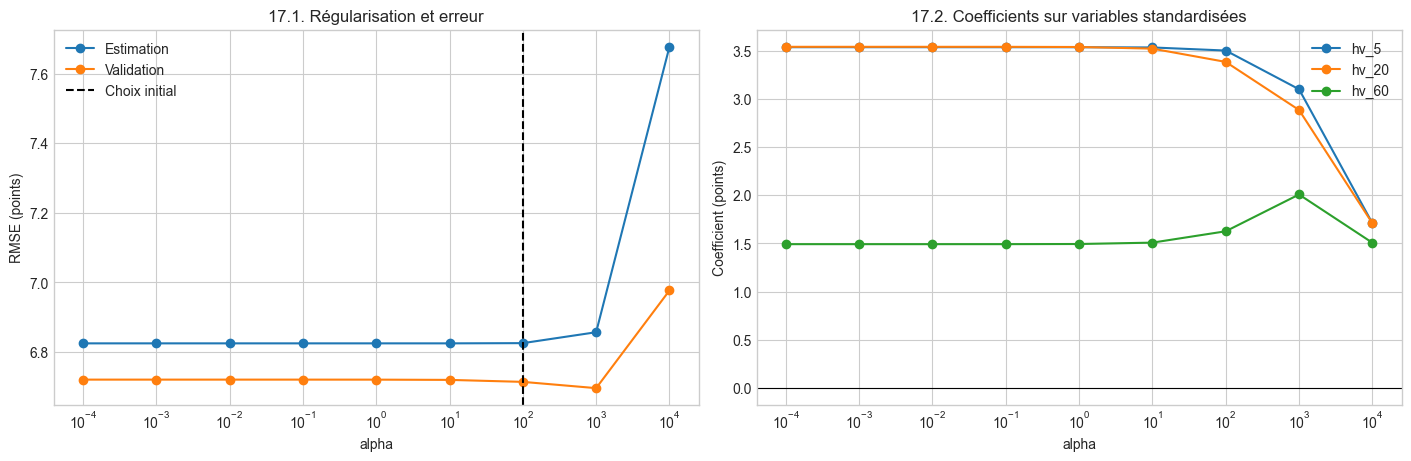

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
axes[0].semilogx(ridge_sensitivity.alpha, ridge_sensitivity.RMSE_estimation, marker='o', label='Estimation')
axes[0].semilogx(ridge_sensitivity.alpha, ridge_sensitivity.RMSE, marker='o', label='Validation')
axes[0].axvline(selected_alpha, color='black', linestyle='--', label='Choix initial')
axes[0].set(title='17.1. Régularisation et erreur', xlabel='alpha', ylabel='RMSE (points)')
axes[0].legend()
for feature in FEATURES:
    axes[1].semilogx(ridge_coefficients.index, 100*ridge_coefficients[feature], marker='o', label=feature)
axes[1].axhline(0, color='black', linewidth=.8)
axes[1].set(title='17.2. Coefficients sur variables standardisées', xlabel='alpha', ylabel='Coefficient (points)')
axes[1].legend()
plt.show()

In [32]:
ridge_subperiod_choices = pd.Series({
    '2010–2012': ridge_sensitivity.loc[ridge_sensitivity.RMSE_2010_2012.idxmin(), 'alpha'],
    '2013–2015': ridge_sensitivity.loc[ridge_sensitivity.RMSE_2013_2015.idxmin(), 'alpha'],
    '2010–2015': expanded_alpha,
}, name='alpha_min_RMSE')
print(ridge_subperiod_choices.to_string())
print('Étendue des coefficients standardisés :')
print((100*ridge_coefficients).agg(['min', 'max']).round(4).to_string())
print('Écart des prévisions à alpha=100 :')
print(ridge_sensitivity[['alpha', 'corrélation_avec_alpha100',
                         'écart_moyen_abs_avec_alpha100']].round(6).to_string(index=False))

2010–2012     100.0
2013–2015    1000.0
2010–2015    1000.0
Étendue des coefficients standardisés :
       hv_5   hv_20   hv_60
min  1.7111  1.7103  1.4930
max  3.5355  3.5396  2.0081
Écart des prévisions à alpha=100 :
     alpha  corrélation_avec_alpha100  écart_moyen_abs_avec_alpha100
    0.0001                   0.999950                       0.059757
    0.0010                   0.999950                       0.059756
    0.0100                   0.999950                       0.059750
    0.1000                   0.999950                       0.059690
    1.0000                   0.999951                       0.059094
   10.0000                   0.999961                       0.053202
  100.0000                   1.000000                       0.000000
 1000.0000                   0.999224                       0.353050
10000.0000                   0.996554                       1.909917


## 18. Gradient Boosting : complexité, interactions et structure des arbres

La recherche étendue reste structurée plutôt qu'exhaustive :

1. interaction `learning_rate × n_estimators` avec profondeur 1 et feuille minimale 10;
2. interaction `max_depth × min_samples_leaf` avec 100 arbres et `learning_rate=0,05`.

Les doublons sont retirés. Cette grille permet de séparer la durée de l'apprentissage de la complexité locale des arbres sans lancer un produit cartésien à quatre dimensions.

In [33]:
gb_config_tuples = set()
for learning_rate in GB_LEARNING_RATES:
    for n_estimators in GB_N_ESTIMATORS:
        gb_config_tuples.add((learning_rate, n_estimators, 1, 10))
for depth in GB_DEPTHS:
    for leaf in GB_LEAVES:
        gb_config_tuples.add((0.05, 100, depth, leaf))
gb_extended_configs = [
    {'learning_rate': lr, 'n_estimators': n, 'max_depth': depth, 'min_samples_leaf': leaf}
    for lr, n, depth, leaf in sorted(gb_config_tuples)
]
assert len(gb_extended_configs) == 39

gb_extended_models = {}
gb_extended_forecasts = {}
gb_sensitivity_rows = []
for config in gb_extended_configs:
    key = tuple(config[k] for k in ['learning_rate', 'n_estimators', 'max_depth', 'min_samples_leaf'])
    model = GradientBoostingRegressor(loss='squared_error', random_state=RANDOM_STATE, **config)
    model.fit(estimation[FEATURES], estimation.rv_5)
    raw_est, pred_est = clipped_prediction(model, estimation)
    raw_val, pred_val_array = clipped_prediction(model, validation)
    pred_val = pd.Series(pred_val_array, index=validation.index)
    gb_extended_models[key] = model
    gb_extended_forecasts[key] = pred_val
    diag = series_diagnostics(validation.rv_5, pred_val)
    high_diag = series_diagnostics(validation.loc[validation_high, 'rv_5'], pred_val.loc[validation_high])
    gb_sensitivity_rows.append({
        **config,
        'RMSE_estimation': 100 * rmse(estimation.rv_5, pred_est),
        **diag,
        'RMSE_Q5_validation': high_diag['RMSE'],
        'sous_estimation_Q5_pct': high_diag['sous_estimation_pct'],
        'RMSE_2010_2012': period_rmse(validation.rv_5, pred_val, validation_early.index),
        'RMSE_2013_2015': period_rmse(validation.rv_5, pred_val, validation_late.index),
        'prévisions_négatives': int((raw_val < 0).sum()),
    })
gb_sensitivity = pd.DataFrame(gb_sensitivity_rows)
best_gb_row = gb_sensitivity.sort_values(
    ['RMSE', 'max_depth', 'min_samples_leaf', 'n_estimators', 'learning_rate']
).iloc[0]
expanded_gb = {
    key: (int(best_gb_row[key]) if key in ['n_estimators', 'max_depth', 'min_samples_leaf'] else float(best_gb_row[key]))
    for key in ['learning_rate', 'n_estimators', 'max_depth', 'min_samples_leaf']
}
expanded_gb_key = tuple(expanded_gb[k] for k in ['learning_rate', 'n_estimators', 'max_depth', 'min_samples_leaf'])
print(f'{len(gb_sensitivity)} configurations distinctes.')
print('Dix meilleures par RMSE de validation :')
print(gb_sensitivity.sort_values('RMSE').head(10).round(4).to_string(index=False))
print(f'Choix étendu par RMSE 2010–2015 uniquement : {expanded_gb}.')

39 configurations distinctes.
Dix meilleures par RMSE de validation :
 learning_rate  n_estimators  max_depth  min_samples_leaf  RMSE_estimation    MAE   RMSE  biais  sous_estimation_pct  sous_estimation_moyenne  sous_estimation_max  variabilité_prévision  RMSE_Q5_validation  sous_estimation_Q5_pct  RMSE_2010_2012  RMSE_2013_2015  prévisions_négatives
          0.10            50          1                10           6.5206 4.7659 6.7121 0.0750              43.5880                   2.3455              58.2290                 1.1707             12.4576                 83.4646          7.6872          5.5637                     0
          0.05           100          1                60           6.5614 4.7666 6.7235 0.1110              43.2558                   2.3278              58.5109                 1.1232             12.4272                 83.0709          7.6976          5.5769                     0
          0.03           200          1                10           6.4594 4.7

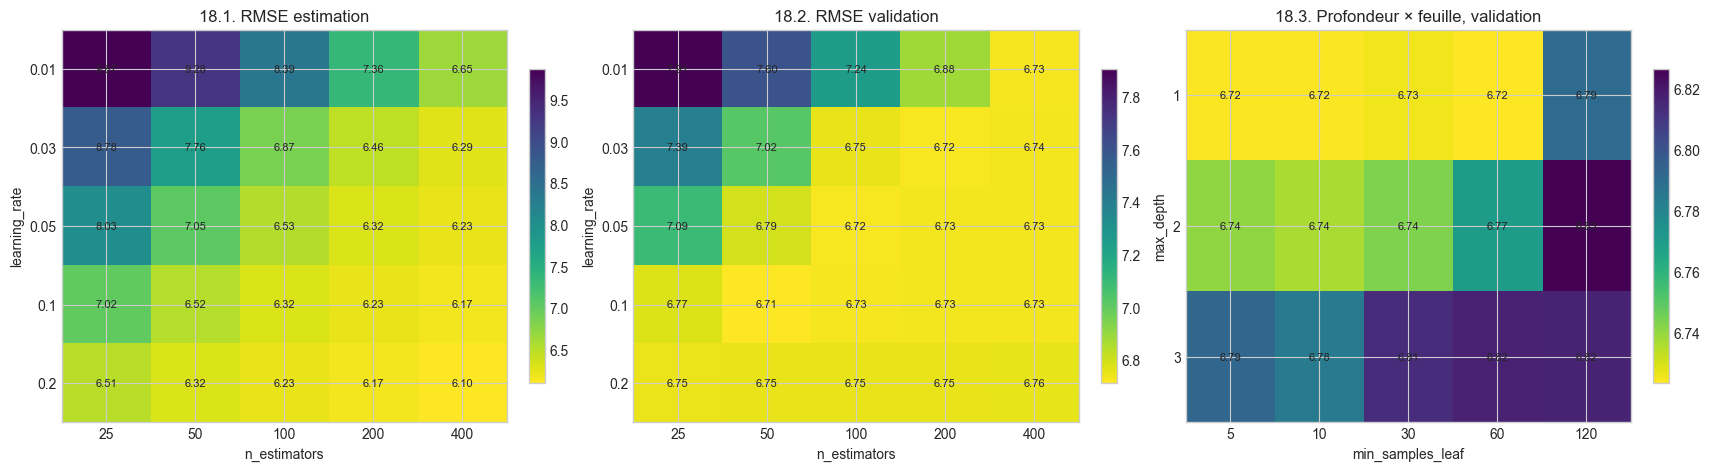

In [34]:
interaction_lr_n = gb_sensitivity.loc[
    (gb_sensitivity.max_depth == 1) & (gb_sensitivity.min_samples_leaf == 10)
]
validation_heat = interaction_lr_n.pivot(index='learning_rate', columns='n_estimators', values='RMSE')
train_heat = interaction_lr_n.pivot(index='learning_rate', columns='n_estimators', values='RMSE_estimation')
depth_leaf = gb_sensitivity.loc[
    np.isclose(gb_sensitivity.learning_rate, .05) & (gb_sensitivity.n_estimators == 100)
]
depth_leaf_heat = depth_leaf.pivot(index='max_depth', columns='min_samples_leaf', values='RMSE')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), constrained_layout=True)
for ax, matrix, title in [
    (axes[0], train_heat, '18.1. RMSE estimation'),
    (axes[1], validation_heat, '18.2. RMSE validation'),
    (axes[2], depth_leaf_heat, '18.3. Profondeur × feuille, validation'),
]:
    image = ax.imshow(matrix.values, aspect='auto', cmap='viridis_r')
    ax.set_xticks(range(len(matrix.columns)), labels=matrix.columns)
    ax.set_yticks(range(len(matrix.index)), labels=matrix.index)
    ax.set(xlabel=matrix.columns.name, ylabel=matrix.index.name, title=title)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, f'{matrix.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
    fig.colorbar(image, ax=ax, shrink=.8)
plt.show()

In [35]:
gb_subperiod_choices = {}
for label, column in [('2010–2012', 'RMSE_2010_2012'), ('2013–2015', 'RMSE_2013_2015'), ('2010–2015', 'RMSE')]:
    row = gb_sensitivity.sort_values(column).iloc[0]
    gb_subperiod_choices[label] = {
        'learning_rate': row.learning_rate,
        'n_estimators': int(row.n_estimators),
        'max_depth': int(row.max_depth),
        'min_samples_leaf': int(row.min_samples_leaf),
        'RMSE': row[column],
    }
print(pd.DataFrame(gb_subperiod_choices).T.round(4).to_string())

underfit_key = (0.01, 25, 1, 10)
original_gb_key = (0.05, 100, 1, 10)
complex_gb_key = (0.05, 100, 3, 5)
representative_gb_keys = list(dict.fromkeys([underfit_key, original_gb_key, expanded_gb_key, complex_gb_key]))
representative_labels = {
    underfit_key: 'lent/court', original_gb_key: 'benchmark initial',
    expanded_gb_key: 'sélection étendue', complex_gb_key: 'plus complexe',
}
gb_forecast_spread = pd.concat(
    {representative_labels[k]: gb_extended_forecasts[k] for k in representative_gb_keys}, axis=1
)
gb_forecast_spread['étendue'] = gb_forecast_spread.max(axis=1) - gb_forecast_spread.min(axis=1)
print('Dates où les configurations représentatives divergent le plus sur validation :')
print((100*gb_forecast_spread.nlargest(10, 'étendue')).round(3).to_string())

           learning_rate  n_estimators  max_depth  min_samples_leaf    RMSE
2010–2012           0.10         200.0        1.0              10.0  7.6843
2013–2015           0.03         100.0        1.0              10.0  5.5525
2010–2015           0.10          50.0        1.0              10.0  6.7121
Dates où les configurations représentatives divergent le plus sur validation :
            lent/court  benchmark initial  sélection étendue  plus complexe  étendue
date                                                                                
2011-08-15      18.942             46.827             46.471         49.917   30.975
2011-08-11      18.942             46.827             46.471         48.677   29.734
2011-08-12      18.942             46.827             46.471         48.677   29.734
2011-08-10      18.942             46.827             46.471         48.245   29.303
2011-08-08      18.942             42.778             42.734         38.113   23.836
2011-08-09      18.942

In [36]:
selected_gb_extended_model = gb_extended_models[expanded_gb_key]
split_rows = []
for tree_index, estimator in enumerate(selected_gb_extended_model.estimators_.ravel()):
    tree = estimator.tree_
    for node in np.where(tree.feature >= 0)[0]:
        split_rows.append({
            'arbre': tree_index,
            'variable': FEATURES[tree.feature[node]],
            'seuil_pct': 100 * tree.threshold[node],
            'observations_pondérées': tree.weighted_n_node_samples[node],
        })
split_table = pd.DataFrame(split_rows)
split_summary = split_table.groupby('variable').agg(
    nombre_coupures=('seuil_pct', 'size'),
    seuil_médian_pct=('seuil_pct', 'median'),
    seuil_q25_pct=('seuil_pct', lambda x: x.quantile(.25)),
    seuil_q75_pct=('seuil_pct', lambda x: x.quantile(.75)),
)
split_summary['importance_impureté'] = pd.Series(
    selected_gb_extended_model.feature_importances_, index=FEATURES
)
print(split_summary.round(4).to_string())

          nombre_coupures  seuil_médian_pct  seuil_q25_pct  seuil_q75_pct  importance_impureté
variable                                                                                      
hv_20                  14           39.9403        18.2988        52.0197               0.3669
hv_5                   18           34.1443        19.8436        54.1384               0.3767
hv_60                  18           17.6569        12.7092        34.0385               0.2564


Les coupures et importances ci-dessus décrivent l'algorithme ajusté, pas des effets causaux ni des contributions indépendantes. `HV5`, `HV20` et `HV60` sont fortement corrélées : une coupure attribuée à une variable peut remplacer une information très proche portée par une autre.

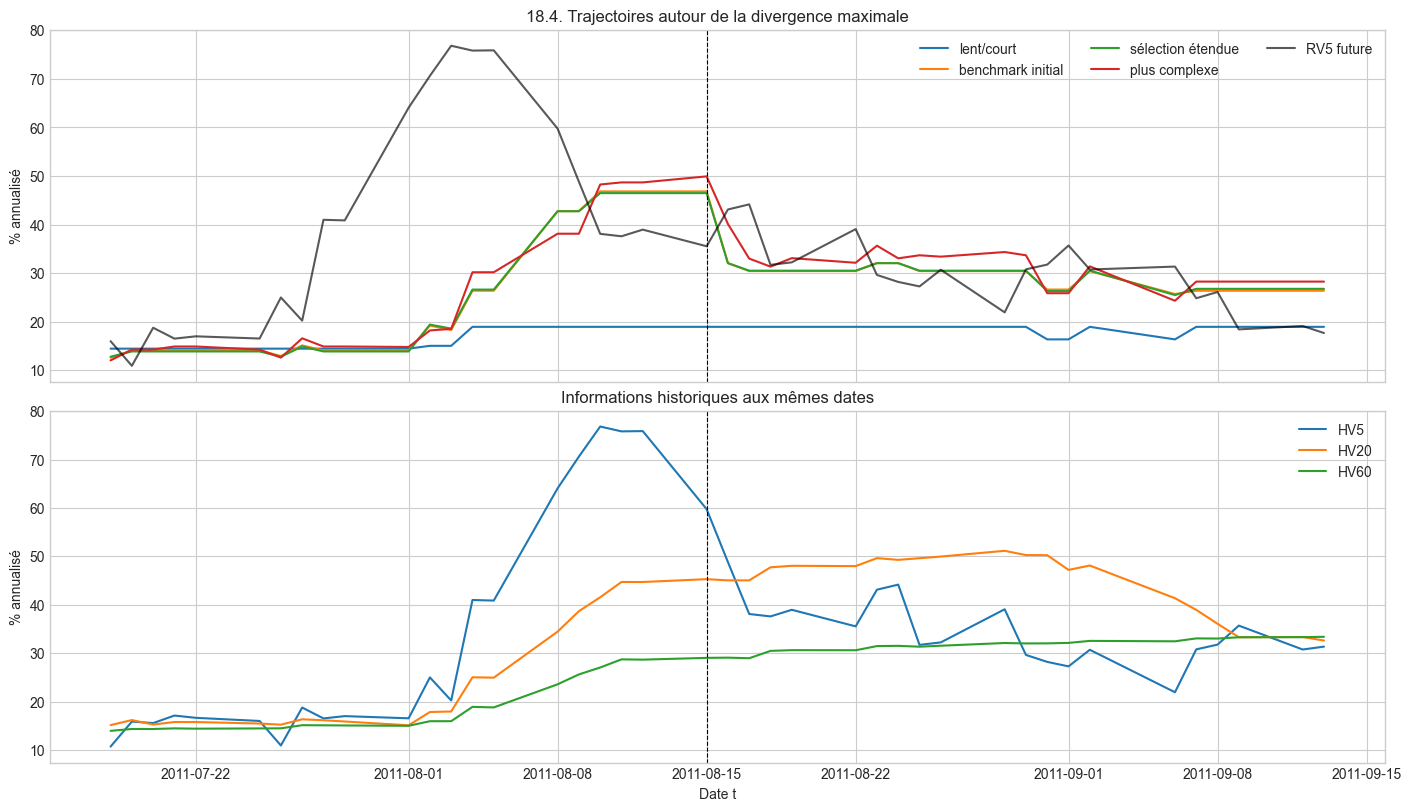

In [37]:
max_spread_date = gb_forecast_spread['étendue'].idxmax()
center = validation.index.get_loc(max_spread_date)
local_index = validation.index[max(0, center-20):min(len(validation), center+21)]
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, constrained_layout=True)
for key in representative_gb_keys:
    label = representative_labels[key]
    axes[0].plot(local_index, 100*gb_extended_forecasts[key].loc[local_index], label=label)
axes[0].plot(local_index, 100*validation.rv_5.loc[local_index], color='black', alpha=.65, label='RV5 future')
axes[0].axvline(max_spread_date, color='black', linestyle='--', linewidth=.8)
axes[0].set(title='18.4. Trajectoires autour de la divergence maximale', ylabel='% annualisé')
axes[0].legend(ncol=3)

axes[1].plot(local_index, 100*validation.hv_5.loc[local_index], label='HV5')
axes[1].plot(local_index, 100*validation.hv_20.loc[local_index], label='HV20')
axes[1].plot(local_index, 100*validation.hv_60.loc[local_index], label='HV60')
axes[1].axvline(max_spread_date, color='black', linestyle='--', linewidth=.8)
axes[1].set(title='Informations historiques aux mêmes dates', ylabel='% annualisé', xlabel='Date t')
axes[1].legend()
plt.show()

## 19. Sélections étendues : résultats séparés du benchmark initial

Les choix ci-dessous sont figés par la RMSE 2010–2015, puis réestimés sur 1990–2015. Ils ne remplacent pas les configurations initiales. Leur évaluation 2016–2019 mesure la sensibilité de nos conclusions à l'élargissement des grilles; elle n'est pas une confirmation indépendante.

In [38]:
extended_predictions = predictions[['rv_5', 'target_start', 'target_end', 'niveau_rv5']].copy()
extended_predictions['Constante'] = predictions['Constante']
extended_predictions['HV20'] = predictions['HV20']

expanded_ewma_path = ewma_extended_paths[expanded_lambda]
expanded_c_final = positive_scale_least_squares(
    expanded_ewma_path.loc[development.index], development.rv_5
)
extended_predictions['EWMA étendue'] = expanded_c_final * expanded_ewma_path.loc[evaluation.index]

ridge_expanded_final = Pipeline([
    ('standardisation', StandardScaler()), ('ridge', Ridge(alpha=expanded_alpha))
])
ridge_expanded_final.fit(development[FEATURES], development.rv_5)
ridge_expanded_raw, ridge_expanded_clipped = clipped_prediction(ridge_expanded_final, evaluation)
extended_predictions['Ridge étendue'] = ridge_expanded_clipped

gb_expanded_final = GradientBoostingRegressor(
    loss='squared_error', random_state=RANDOM_STATE, **expanded_gb
)
gb_expanded_final.fit(development[FEATURES], development.rv_5)
gb_expanded_raw, gb_expanded_clipped = clipped_prediction(gb_expanded_final, evaluation)
extended_predictions['Boosting étendu'] = gb_expanded_clipped

EXTENDED_MODELS = ['Constante', 'HV20', 'EWMA étendue', 'Ridge étendue', 'Boosting étendu']
assert extended_predictions[EXTENDED_MODELS].notna().all().all()
assert extended_predictions.index.equals(predictions.index) and len(extended_predictions) == 1001
assert int((ridge_expanded_raw < 0).sum()) == 0
assert int((gb_expanded_raw < 0).sum()) == 0

comparison_columns = pd.DataFrame({
    'configuration_initiale': [selected_lambda, selected_alpha, str({**selected_gb, 'learning_rate': .05, 'n_estimators': 100})],
    'configuration_étendue': [expanded_lambda, expanded_alpha, str(expanded_gb)],
}, index=['EWMA', 'Ridge', 'Gradient Boosting'])
print(comparison_columns.to_string())
print(f'Facteur EWMA étendu réestimé sur 1990–2015 : {expanded_c_final:.6f}.')

                                                                                 configuration_initiale                                                               configuration_étendue
EWMA                                                                                                0.9                                                                                 0.9
Ridge                                                                                             100.0                                                                              1000.0
Gradient Boosting  {'max_depth': 1, 'min_samples_leaf': 10, 'learning_rate': 0.05, 'n_estimators': 100}  {'learning_rate': 0.1, 'n_estimators': 50, 'max_depth': 1, 'min_samples_leaf': 10}
Facteur EWMA étendu réestimé sur 1990–2015 : 0.924348.


In [39]:
extended_global_metrics = pd.DataFrame({
    model: model_metrics(extended_predictions, model) for model in EXTENDED_MODELS
}).T
initial_vs_extended = pd.DataFrame({
    'initial_MAE': global_metrics.loc[['EWMA', 'Ridge', 'Gradient Boosting'], 'MAE'].to_numpy(),
    'étendue_MAE': extended_global_metrics.loc[['EWMA étendue', 'Ridge étendue', 'Boosting étendu'], 'MAE'].to_numpy(),
    'initial_RMSE': global_metrics.loc[['EWMA', 'Ridge', 'Gradient Boosting'], 'RMSE'].to_numpy(),
    'étendue_RMSE': extended_global_metrics.loc[['EWMA étendue', 'Ridge étendue', 'Boosting étendu'], 'RMSE'].to_numpy(),
}, index=['EWMA', 'Ridge', 'Gradient Boosting'])
initial_vs_extended['variation_MAE'] = initial_vs_extended.étendue_MAE - initial_vs_extended.initial_MAE
initial_vs_extended['variation_RMSE'] = initial_vs_extended.étendue_RMSE - initial_vs_extended.initial_RMSE
print('Métriques globales des sélections étendues :')
print(extended_global_metrics.round(3).to_string())
print('Comparaison aux configurations initiales ; négatif = amélioration descriptive :')
print(initial_vs_extended.round(4).to_string())

Métriques globales des sélections étendues :
                      n    MAE   RMSE  biais_signé  sous_estimation_pct  sous_estimation_moyenne_toutes_dates  ampleur_moyenne_si_sous_estimation  sous_estimation_maximale
Constante        1001.0  7.054  8.129        3.639               21.079                                 1.708                               8.102                    31.199
HV20             1001.0  4.839  6.796        0.873               36.663                                 1.983                               5.409                    33.904
EWMA étendue     1001.0  4.295  6.199        0.029               40.859                                 2.133                               5.220                    34.568
Ridge étendue    1001.0  4.428  6.098        0.887               34.166                                 1.770                               5.182                    32.834
Boosting étendu  1001.0  4.801  6.333        1.721               26.474                        

In [40]:
extended_yearly_rows = []
extended_conditional_rows = []
for year, group in extended_predictions.groupby(extended_predictions.index.year):
    for model in EXTENDED_MODELS:
        extended_yearly_rows.append({'année': year, 'modèle': model, **model_metrics(group, model).to_dict()})
for level in labels:
    group = extended_predictions.loc[extended_predictions.niveau_rv5.eq(level)]
    for model in EXTENDED_MODELS:
        extended_conditional_rows.append({'niveau': level, 'modèle': model, **model_metrics(group, model).to_dict()})
extended_yearly = pd.DataFrame(extended_yearly_rows)
extended_conditional = pd.DataFrame(extended_conditional_rows)
print('Stabilité annuelle :')
print(extended_yearly[['année', 'modèle', 'MAE', 'RMSE', 'biais_signé',
                       'sous_estimation_pct', 'sous_estimation_moyenne_toutes_dates']]
      .round(3).to_string(index=False))
print('Résultats Q5 :')
print(extended_conditional.loc[extended_conditional.niveau.eq('Q5'),
      ['modèle', 'n', 'MAE', 'RMSE', 'biais_signé', 'sous_estimation_pct',
       'sous_estimation_moyenne_toutes_dates', 'sous_estimation_maximale']]
      .round(3).to_string(index=False))

Stabilité annuelle :
 année          modèle   MAE  RMSE  biais_signé  sous_estimation_pct  sous_estimation_moyenne_toutes_dates
  2016       Constante 6.541 7.422        3.122               23.016                                 1.710
  2016            HV20 4.681 6.811        1.257               34.524                                 1.712
  2016    EWMA étendue 4.226 6.202        0.325               38.889                                 1.950
  2016   Ridge étendue 4.369 6.048        1.092               33.333                                 1.638
  2016 Boosting étendu 4.631 6.068        1.654               30.159                                 1.488
  2017       Constante 8.111 8.640        8.090                1.594                                 0.010
  2017            HV20 2.974 3.565        0.569               35.458                                 1.203
  2017    EWMA étendue 2.838 3.496        0.011               42.231                                 1.414
  2017   Ridge é

In [41]:
extended_error_pct = pd.DataFrame({
    model: 100*(extended_predictions[model] - extended_predictions.rv_5)
    for model in EXTENDED_MODELS
})
extended_concentration_rows = []
for model in EXTENDED_MODELS:
    squared = extended_error_pct[model].pow(2).sort_values(ascending=False)
    extended_concentration_rows.append({
        'modèle': model,
        'SSE_top_1pct': 100*squared.iloc[:int(np.ceil(.01*len(squared)))].sum()/squared.sum(),
        'SSE_top_5pct': 100*squared.iloc[:int(np.ceil(.05*len(squared)))].sum()/squared.sum(),
        'SSE_top_10pct': 100*squared.iloc[:int(np.ceil(.10*len(squared)))].sum()/squared.sum(),
    })
extended_concentration = pd.DataFrame(extended_concentration_rows).set_index('modèle')

extended_large_under = extended_error_pct.le(-COMMON_ERROR_THRESHOLD_PCT)
extended_large_over = extended_error_pct.ge(COMMON_ERROR_THRESHOLD_PCT)
extended_common = pd.DataFrame({
    'sous': extended_large_under.sum(axis=1),
    'sur': extended_large_over.sum(axis=1),
})
extended_common_summary = pd.DataFrame({
    'observations': [
        int((extended_common.sous >= 4).sum()), int((extended_common.sous == 5).sum()),
        int((extended_common.sur >= 4).sum()), int((extended_common.sur == 5).sum()),
    ],
    'épisodes': [
        episode_count(extended_common.sous >= 4), episode_count(extended_common.sous == 5),
        episode_count(extended_common.sur >= 4), episode_count(extended_common.sur == 5),
    ],
}, index=['sous-estimation ≥4/5', 'sous-estimation 5/5',
          'surestimation ≥4/5', 'surestimation 5/5'])
print('Concentration :')
print(extended_concentration.round(2).to_string())
print('Échecs communs avec le seuil initial inchangé :')
print(extended_common_summary.to_string())

Concentration :
                 SSE_top_1pct  SSE_top_5pct  SSE_top_10pct
modèle                                                    
Constante               10.79         25.17          35.89
HV20                    16.93         45.41          62.61
EWMA étendue            21.02         52.08          66.34
Ridge étendue           20.25         48.33          61.05
Boosting étendu         18.68         43.29          55.63
Échecs communs avec le seuil initial inchangé :
                      observations  épisodes
sous-estimation ≥4/5            45        13
sous-estimation 5/5             34        11
surestimation ≥4/5               9         4
surestimation 5/5                1         1


In [42]:
extended_offset_rows = []
for offset in range(HORIZON):
    spaced = extended_predictions.iloc[offset::HORIZON]
    assert (spaced.target_start.iloc[1:].to_numpy() > spaced.target_end.iloc[:-1].to_numpy()).all()
    for scope, subset in [('global', spaced), ('Q5', spaced.loc[spaced.niveau_rv5.eq('Q5')])]:
        for model in EXTENDED_MODELS:
            values = model_metrics(subset, model)
            extended_offset_rows.append({
                'décalage': offset, 'périmètre': scope, 'modèle': model,
                'MAE': values.MAE, 'RMSE': values.RMSE,
                'sous_estimation_moyenne': values.sous_estimation_moyenne_toutes_dates,
            })
extended_offsets = pd.DataFrame(extended_offset_rows)
extended_offset_ranges = extended_offsets.groupby(['périmètre', 'modèle'])[
    ['MAE', 'RMSE', 'sous_estimation_moyenne']
].agg(['min', 'max'])
print(extended_offset_ranges.round(3).to_string())

                              MAE            RMSE         sous_estimation_moyenne        
                              min     max     min     max                     min     max
périmètre modèle                                                                         
Q5        Boosting étendu   8.697  10.070  11.071  12.518                   8.695  10.025
          Constante        11.172  12.051  12.411  13.315                  11.172  12.051
          EWMA étendue      8.445  10.075  11.401  12.982                   8.386  10.035
          HV20              8.694   9.735  11.480  12.676                   8.290   9.617
          Ridge étendue     8.743   9.990  11.175  12.561                   8.724   9.990
global    Boosting étendu   4.688   4.935   6.229   6.513                   1.475   1.591
          Constante         7.005   7.159   8.062   8.225                   1.691   1.744
          EWMA étendue      4.181   4.493   6.009   6.379                   2.054   2.213
          

## 20. Synthèse critique de l'approfondissement

Les résultats permettent de distinguer quatre niveaux : mécanismes mathématiques, comportement observé sur validation, sensibilité exploratoire sur 2016–2019 et implications financières encore inconnues. Les critères de sélection sont restés fixés avant l'examen de 2016–2019.

In [43]:
print('SÉLECTIONS ÉTENDUES, FIXÉES AVANT 2016')
print(f'EWMA : lambda {selected_lambda:.2f} → {expanded_lambda:.2f}.')
print(f'Ridge : alpha {selected_alpha:g} → {expanded_alpha:g}.')
print(f'Boosting : {expanded_gb}.')
print('Choix par sous-périodes de validation :')
print('EWMA:', ewma_subperiod_choices.to_dict())
print('Ridge:', ridge_subperiod_choices.to_dict())
print('Boosting:', gb_subperiod_choices)
print('Évaluation exploratoire des sélections étendues :')
print(extended_global_metrics[['MAE', 'RMSE', 'biais_signé', 'sous_estimation_pct',
                               'sous_estimation_moyenne_toutes_dates',
                               'sous_estimation_maximale']].round(3).to_string())
print('Q5 :')
print(extended_conditional.loc[extended_conditional.niveau.eq('Q5'),
      ['modèle', 'MAE', 'RMSE', 'sous_estimation_pct',
       'sous_estimation_moyenne_toutes_dates']].round(3).to_string(index=False))

SÉLECTIONS ÉTENDUES, FIXÉES AVANT 2016
EWMA : lambda 0.90 → 0.90.
Ridge : alpha 100 → 1000.
Boosting : {'learning_rate': 0.1, 'n_estimators': 50, 'max_depth': 1, 'min_samples_leaf': 10}.
Choix par sous-périodes de validation :
EWMA: {'2010–2012': 0.9, '2013–2015': 0.97, '2010–2015': 0.9}
Ridge: {'2010–2012': 100.0, '2013–2015': 1000.0, '2010–2015': 1000.0}
Boosting: {'2010–2012': {'learning_rate': np.float64(0.1), 'n_estimators': 200, 'max_depth': 1, 'min_samples_leaf': 10, 'RMSE': np.float64(7.684292654975911)}, '2013–2015': {'learning_rate': np.float64(0.03), 'n_estimators': 100, 'max_depth': 1, 'min_samples_leaf': 10, 'RMSE': np.float64(5.552531329459988)}, '2010–2015': {'learning_rate': np.float64(0.1), 'n_estimators': 50, 'max_depth': 1, 'min_samples_leaf': 10, 'RMSE': np.float64(6.712105194429774)}}
Évaluation exploratoire des sélections étendues :
                   MAE   RMSE  biais_signé  sous_estimation_pct  sous_estimation_moyenne_toutes_dates  sous_estimation_maximale
Const

### 20.1. Interprétation et limites

**EWMA.** La frontière initiale ne masquait pas un optimum plus réactif : `lambda=0,90`, soit une demi-vie de 6,58 séances, reste le minimum de RMSE sur 2010–2015. La courbe est peu pentue entre 0,85 et 0,90, puis se dégrade dans les deux directions. À `lambda=0,70`, la prévision varie davantage et présente un biais de sous-estimation plus marqué; à `lambda=0,99`, elle devient très lisse, réagit lentement et sous-estime 93,7 % des observations de `Q5` de validation. Le choix n'est cependant pas stable entre sous-périodes : 0,90 sur 2010–2012 contre 0,97 sur 2013–2015.

**Ridge.** De `alpha=0,0001` à 10, les prévisions sont pratiquement identiques. Étendre la grille déplace le minimum de validation de 100 à 1000, mais le gain de RMSE n'est que de 0,018 point. Les trajectoires à 100 et 1000 restent corrélées à 0,9992 et ne diffèrent en moyenne que de 0,353 point. `alpha=10000` contracte nettement les coefficients et détériore les deux périodes : c'est une manifestation de sous-apprentissage. Surtout, `alpha=1000` dégrade ensuite la MAE de 0,061 point et la RMSE de 0,009 sur 2016–2019 par rapport au choix initial. Le minimum de validation ne représente donc pas une amélioration robuste.

**Gradient Boosting.** Les meilleures configurations utilisent toutes des arbres de profondeur 1. Le choix étendu (`learning_rate=0,10`, 50 arbres) et le choix initial (`0,05`, 100 arbres) correspondent à des budgets d'apprentissage proches et donnent des résultats presque identiques en 2016–2019 : −0,0045 point de MAE et −0,0005 de RMSE. Accroître le nombre d'arbres ou la profondeur réduit l'erreur d'estimation sans améliorer systématiquement la validation, ce qui révèle un début de surapprentissage plutôt qu'un bénéfice assuré de la complexité. Les configurations retenues diffèrent entre 2010–2012 et 2013–2015. Les coupures sont réparties entre les trois horizons; leur attribution ne mesure pas des effets indépendants puisque `HV5`, `HV20` et `HV60` sont liées.

**Fiabilité partagée.** L'élargissement ne change pas la conclusion centrale. Dans `Q5`, `HV20` conserve la plus faible MAE (9,243) et la plus faible fréquence de sous-estimation parmi les méthodes dynamiques. Les sélections étendues sous-estiment encore 91,6 % à 96,2 % des dates de `Q5`. Avec le même seuil absolu de 10,931 points, au moins quatre modèles connaissent une grande sous-estimation sur 45 dates et 13 épisodes, contre 44 dates et 13 épisodes dans le benchmark initial. Les cinq échouent ensemble sur 34 dates et 11 épisodes, contre 33 et 11 auparavant. La sensibilité des paramètres modifie donc les trajectoires et les compromis, mais explique peu les échecs communs.

**Interprétation financière.** Une mémoire plus rapide, une régularisation plus forte ou des arbres plus complexes peuvent déplacer le biais et la fréquence des sous-estimations. Rien ne montre cependant qu'un de ces déplacements améliore une décision financière : aucune perte, exposition ou fonction de coût n'est définie. Une forte `RV5` ne signifie pas automatiquement une perte.

**Limites.** L'examen de 56 configurations sur le même bloc 2010–2015 accroît le risque de surajustement de sélection. Les choix par sous-périodes reposent sur moins d'observations et ne sont pas des validations indépendantes. Les trajectoires autour des grands rendements sont sélectionnées rétrospectivement. La période 2016–2019 est déjà connue; `RV5` est bruitée, chevauchante et insensible au signe. Aucune inférence statistique, validation externe, fonction de coût financier ou relation causale n'est introduite.

**Conclusion.** Les hyperparamètres contrôlent clairement la réactivité et le lissage, mais les minima de validation sont plats et temporellement instables. La sophistication supplémentaire ne modifie pas substantiellement notre compréhension : plusieurs méthodes exploitent utilement la persistance moyenne, tandis que les hausses futures difficiles restent largement communes aux modèles.

**Arrêt.** Cet approfondissement clôt l'expérience autorisée. Aucune autre modélisation ou extension n'est lancée sans validation explicite.